# openpilot supercombo on KITScenes: change the image, see the plan

This is a short companion to [the image-calibration notebook](openpilot_drv_supcombo_kitscenes_image_calibration.ipynb), which measured about a hundred image settings on ten turns. This one runs no sweeps. You edit one config and see what it does:

1. **Five turns, as the recorded run planned them.** For each turn:
    - the four images the model was given (each view's two frames);
    - the GT and the plan drawn on the keyframe;
    - the warps that cut each view out of the camera image, and the road's homography into each view;
    - the car's two front cameras, either of which a config can feed the model, and the 65° cut comma's own camera would make of each.
2. **One turn, `FOCUS`: how the heights and speeds are measured.** Both the real values and the values the model reads.
3. **`CONFIG`, a change to what the model is fed, on that turn.** Edit it and re-run the cell. The model plans again, and the new plan is drawn beside stock's (or beside any other config). A `noise` row shows how much a half-pixel shift alone changes each number. A config can change:
    - the image: its geometry, sampling and tone, as in the image-calibration notebook;
    - the source: which front camera, and a cut of it to another field of view, such as comma's 65°;
    - the intent: whether the route's turn is sent as openpilot's desire.
4. **The same config on all five turns**, scored against stock (or any other config) on ADE, alignment with the GT and the speed profile. Each change is judged against a noise floor.
5. **Several configs side by side on all five turns**, for example stock, with intent, on the other camera, and both.

On every view the model is shown, a solid white line marks the row openpilot expects the horizon on: row 47.6 of img's 256, row 151.8 of big_img's.

**How it runs**
- **The code** is in [`openpilot_drv_supcombo_image_tweak_lib.py`](openpilot_drv_supcombo_image_tweak_lib.py), next to this notebook. Restart the kernel after editing it.
- **Paddock never imports a model, and neither does this notebook.**
    - The model runs in [`openpilot_drv_supcombo_image_node.py`](openpilot_drv_supcombo_image_node.py). It is the stock adapter; only the way it makes the warps and tensors is changed.
    - The node runs in openpilot's own interpreter, the same way `paddock run` launches a model. The notebook sends it matrices and lookup tables over localhost.
    - The checks before part 3 show that, with no config, the node is the stock adapter bit for bit.
- **It runs on CPU by default.** The nodes start the first time they are needed, one per turn.
- **Every result is cached** under `{runs}/kitscenes/_analysis/openpilot/image_tweak/`. The cache key is the matrices sent, the sample, the camera and cut it came from, the desire, the device and a hash of the code. Running the same config again costs nothing. A cut (`fov_deg`) is staged once per turn, as raw frames under the same directory.

**The committed outputs are stock.** `CONFIG` leaves the image unchanged and part 5 has the one arm, stock, so parts 3–5 show stock against itself. They were made on CPU by `.venv/bin/jupyter execute --inplace`.

In [1]:
import sys

import pandas as pd

from paddock.config import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT / "tools/models/openpilot/analysis"))  # the lib, beside this notebook
import openpilot_drv_supcombo_image_tweak_lib as T

pd.set_option("display.max_columns", 50)  # part 4's per-turn table has 31 columns

## Parameters

- **`SCENES`**: the five turns. Wherever a cell takes a key, the key can be:
    - a sample id;
    - a label such as `"03ed2585/40"` (the first 8 characters of the scene id, then the keyframe);
    - a unique prefix of either.
- **`FOCUS`**: the turn that parts 2 and 3 work on.
- **`RUN_ID`**: the recorded stock run that part 1 draws.
- **`DEVICE`**: `"cpu"`, or `"cuda"` if a GPU is free. **`NODES`** is the number of model processes; **`THREADS`** is the threads each one uses.
- **`HEIGHT`**: the camera's real height. It is used to draw the road and by the knobs that move the camera. One of:
    - `"context"`: the map's height for each scene, near 1.88 m;
    - `"harness"`: about 2.0 m;
    - a number in metres.
- **`OVERRIDES`**: tag parameters for the turn classes, for example `{"curv_under": 0.6}`.
- **`RECOMPUTE`**: ignore the cached results.
- **`OVERLAY`**: where the GT and the plans are drawn.
    - `"img"`: the keyframe of the narrow view.
    - Add `"big_img"` for the wide view, or `"camera"` for the photo.

In [6]:
SCENES = [
    "dbba76d9-91ec-b44f-f3d3-6348d55f7849/130",  # left in 18 m: not planned
    "5bf1c78c-46c7-2e4d-7295-00a1de902965/40",  # left in 18 m: the wrong way
    "8c501afb-5a9b-e881-1c7d-99c21f39b1cc/40",  # left in 17 m: understeer
    "03ed2585-0729-92ad-98af-fdd9ac1c3a80/40",  # right in 28 m: understeer by slowing; the worst ADE
    "b8002a79-ac44-b7bb-c7d6-0136e49e016f/40",  # right in 64 m at 12.8 m/s: matched (a control)
]
FOCUS = "dbba76d9/130"
RUN_ID = "20260930T154018-242869"  # the open-loop notebook's stock re-run
DEVICE = "cpu"
NODES, THREADS = 5, 8
HEIGHT = "context"
OVERRIDES = {}
RECOMPUTE = False
OVERLAY = ("img",)  # on 4 of the 5 turns img shows little or none of the path; add "big_img" or "camera"

lab = T.Lab(
    SCENES,
    RUN_ID,
    device=DEVICE,
    nodes=NODES,
    threads=THREADS,
    height=HEIGHT,
    overrides=OVERRIDES,
    recompute=RECOMPUTE,
)

5 turns; code 133d484051 (openpilot 555f48c5d); model on cpu, 5 node(s); cache {runs}/kitscenes/_analysis/openpilot/image_tweak


## 1 Five turns, as the recorded run planned them

These five come from the image-calibration notebook's ten. They cover three ways stock gets a near turn wrong (no turn, the wrong way, too little), plus one far turn it gets right:

| turn | route | speed | stock |
|---|---|---|---|
| dbba76d9/130 | left in 18 m | 3.9 m/s | does not plan the turn |
| 5bf1c78c/40 | left in 18 m | 4.2 m/s | turns the wrong way |
| 8c501afb/40 | left in 17 m | 4.2 m/s | turns too little |
| 03ed2585/40 | right in 28 m | 4.9 m/s | keeps to the GT's path but slows, so by 3 s it has turned too little; the worst ADE |
| b8002a79/40 | right in 64 m | 12.8 m/s | matches the GT's turn over 3 s |

The columns, here and in every table below:
- **`mode`**: the open-loop notebook's turn class. The first match wins:
    - `not_planned`: the plan's heading changes by less than 15° over its 10 s;
    - `wrong_way`: it turns 15° or more away from the route;
    - otherwise the class compares the plan's turn with the GT's over 3 s: `understeer` under 0.7 of it, `oversteer` 1.3 or more, `matched` in between.
- **`ade`**: the benchmark's score, the mean distance from the GT over 3 s (m).
- **`ade_long`**: the same over the GT's whole length, up to 10 s.
- **`lat`**: the benchmark's mean lateral error over 3 s (m), between the plan and the GT at the same time.
- **`path_err`**: the mean distance from the plan's waypoints over 3 s to the GT's path, wherever along it they fall (m). It ignores timing: a plan on the GT's line scores 0, however slowly it drives it.
- **`dpsi`, `gt_dpsi`**: the plan's and the GT's heading change over 3 s (deg). Positive is toward the route.
- **`turn_frac`**: the plan's share of the GT's turn, over the GT's whole length.
- **`speed_rmse`**: the RMS difference between the plan's and the GT's speeds over 3 s, per 0.5 s step (m/s).
- **`v0_ratio`**: the speed of the plan's first step over the GT's.
- **`head_ratio`**: the pose head's speed over the car's.
- **`plan_v0`**: the plan's own start speed (m/s).
- **`cam_h`, `h_map`**: the camera height the model reads, and the real height from the map (m). Part 2 says how each is measured.
- **`p_turn`** (parts 3–5): the probability the model's desire-state head gives the route's turn (turn left or turn right) at the keyframe. It shows whether the model thinks it is turning, whether or not it was sent the intent.

In [3]:
lab.recorded_table().round(3)

,route,v,mode,ade,ade_long,lat,path_err,dpsi,gt_dpsi,turn_frac,speed_rmse,v0_ratio,head_ratio,plan_v0,cam_h,h_map
key,,,,,,,,,,,,,,,,
dbba76d9/130,left in 18 m,3.867,not_planned,2.318,10.124,1.896,0.851,1.095,61.474,-0.002,0.946,0.798,0.896,3.352,1.413,1.931
5bf1c78c/40,left in 18 m,4.175,wrong_way,1.716,15.603,0.859,0.336,-4.429,34.047,-0.965,1.223,0.805,0.766,3.170,1.383,1.976
8c501afb/40,left in 17 m,4.211,understeer,0.743,15.503,0.465,0.254,41.023,62.876,0.371,0.411,0.792,0.722,3.012,1.384,1.856
03ed2585/40,right in 28 m,4.925,understeer,2.858,13.512,1.873,0.191,27.856,52.506,1.007,2.441,0.899,0.708,4.402,1.361,1.867
b8002a79/40,right in 64 m,12.751,matched,2.137,12.633,0.098,0.383,13.067,13.261,0.622,1.367,0.915,0.883,11.555,1.633,1.878


Each figure shows one turn:
- **Top row:**
    - the camera's keyframe, with the outlines of img (yellow) and big_img (cyan) and the road at its real height;
    - the paths seen from above;
    - the speed and the heading at each 0.5 s step.
- **Bottom row:** the four images the model was given. Each view has two frames: the frame 0.2 s before the keyframe, then the keyframe. The GT and the plan are drawn on the keyframe of each `OVERLAY` view, placed where the real camera sees them.

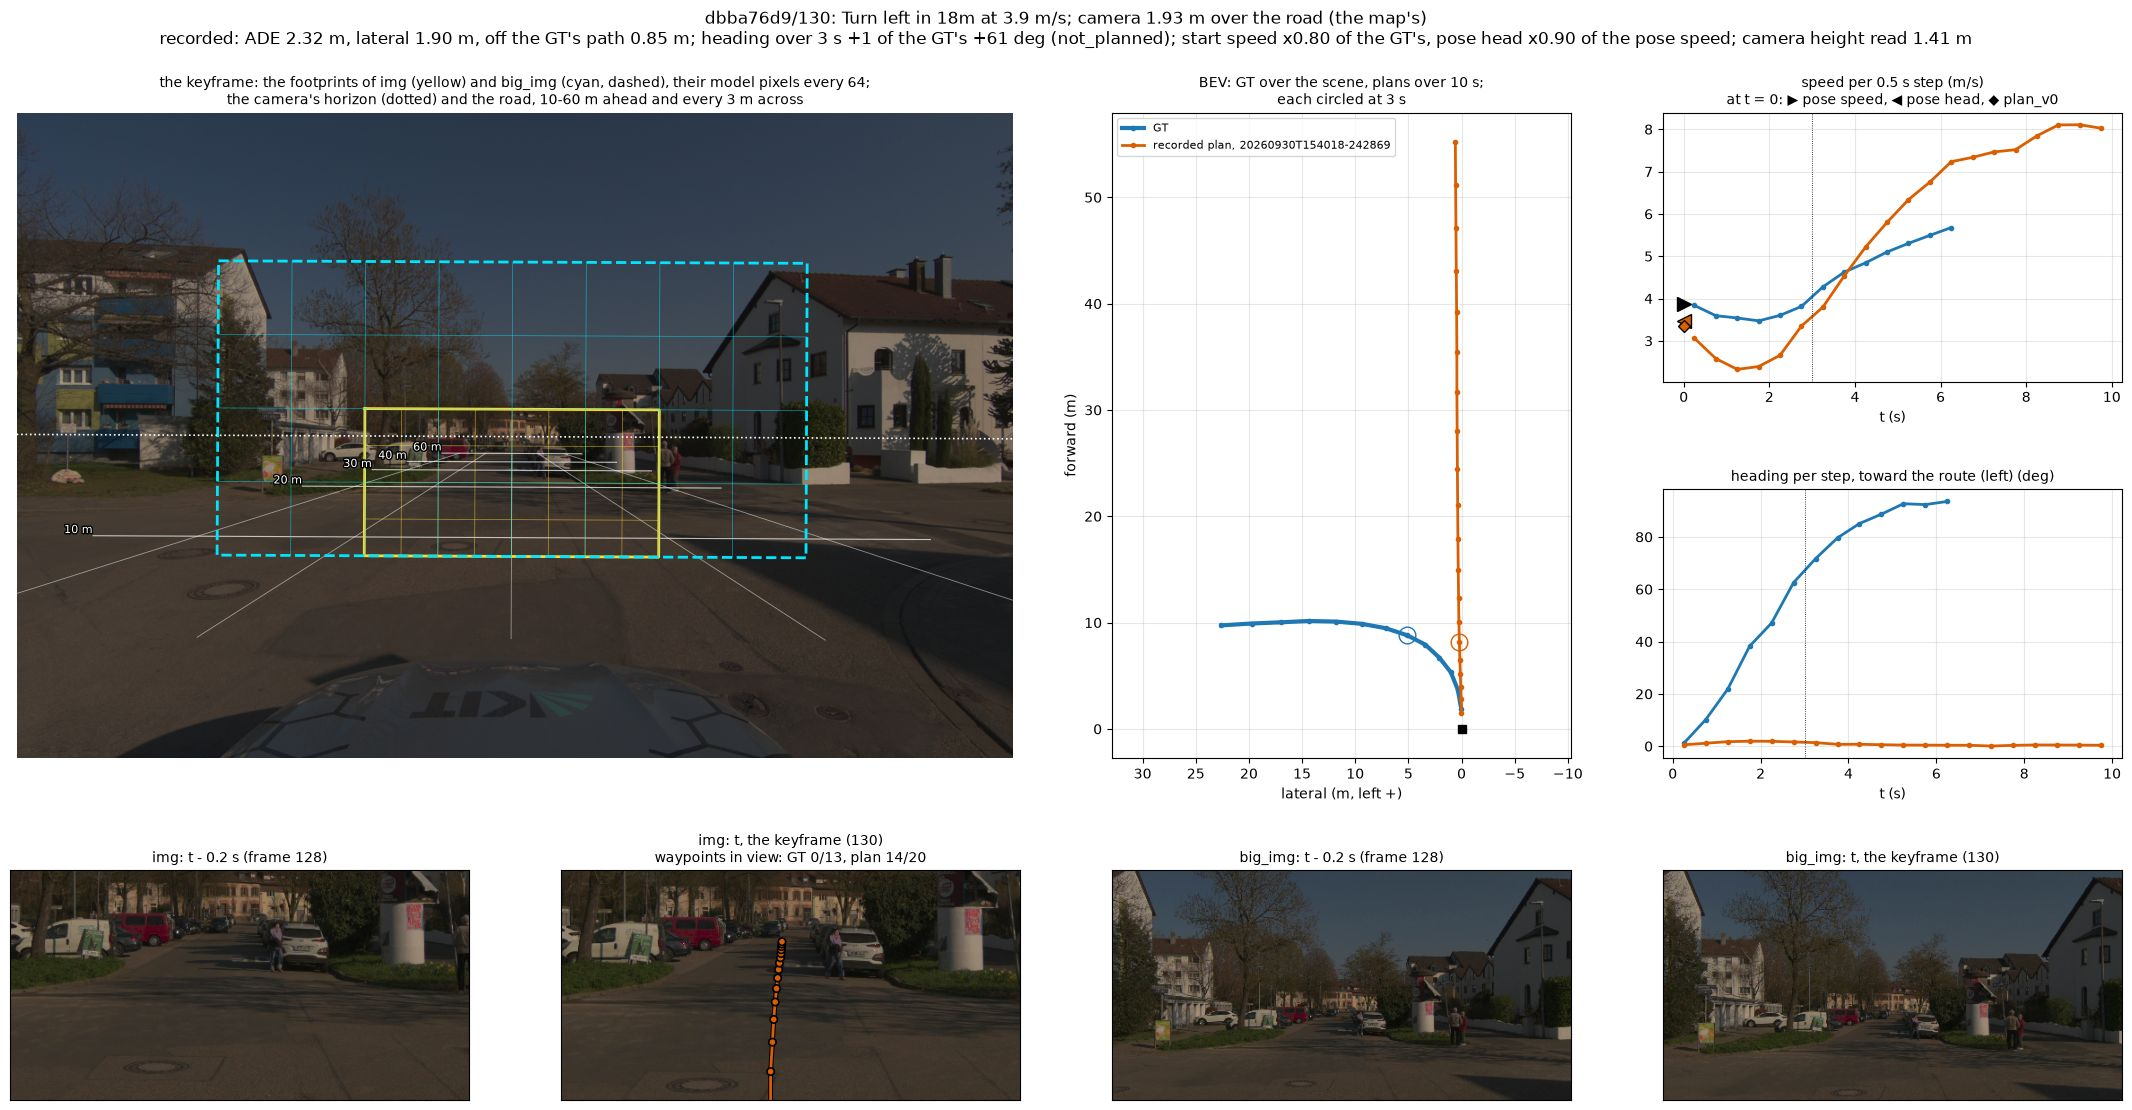

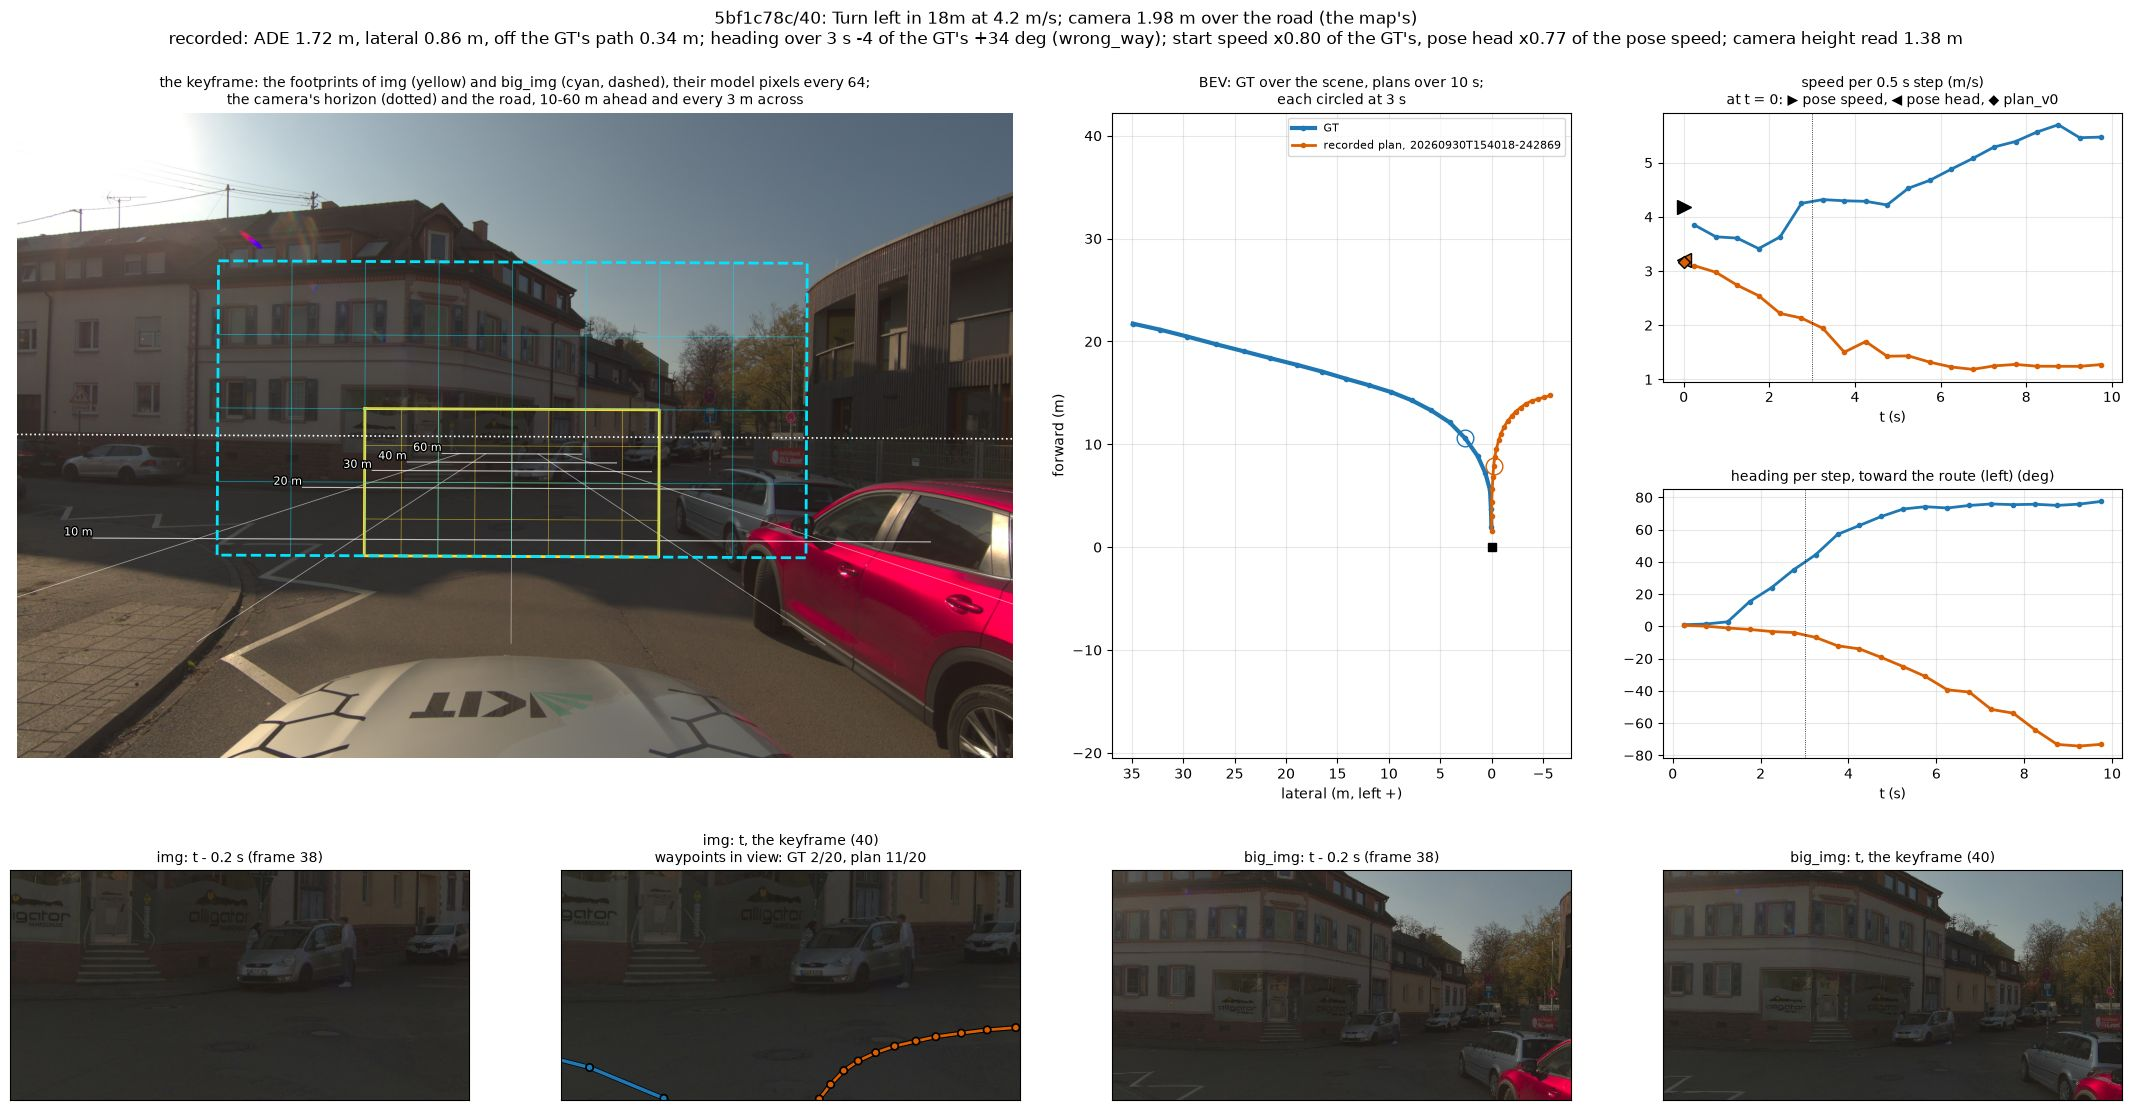

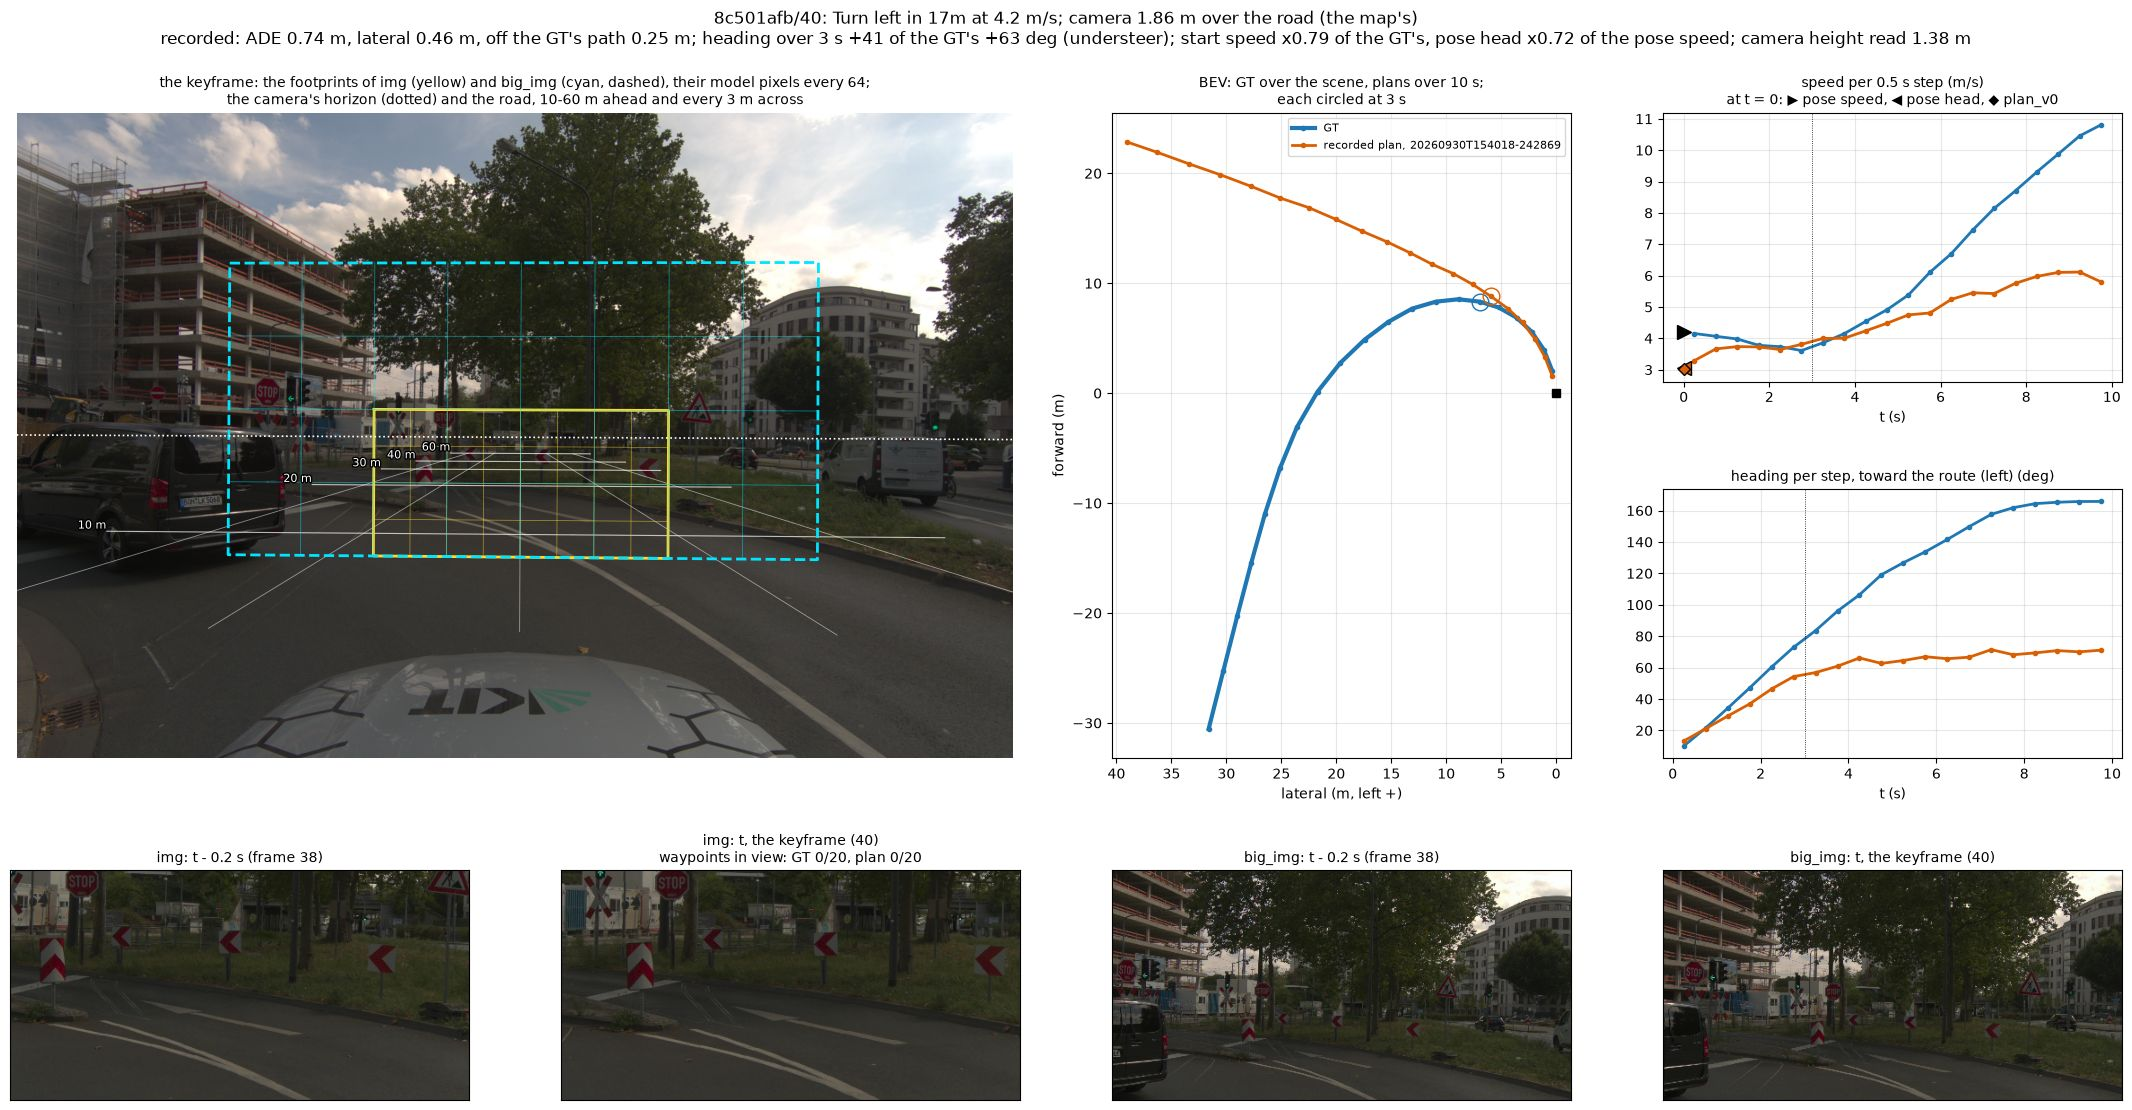

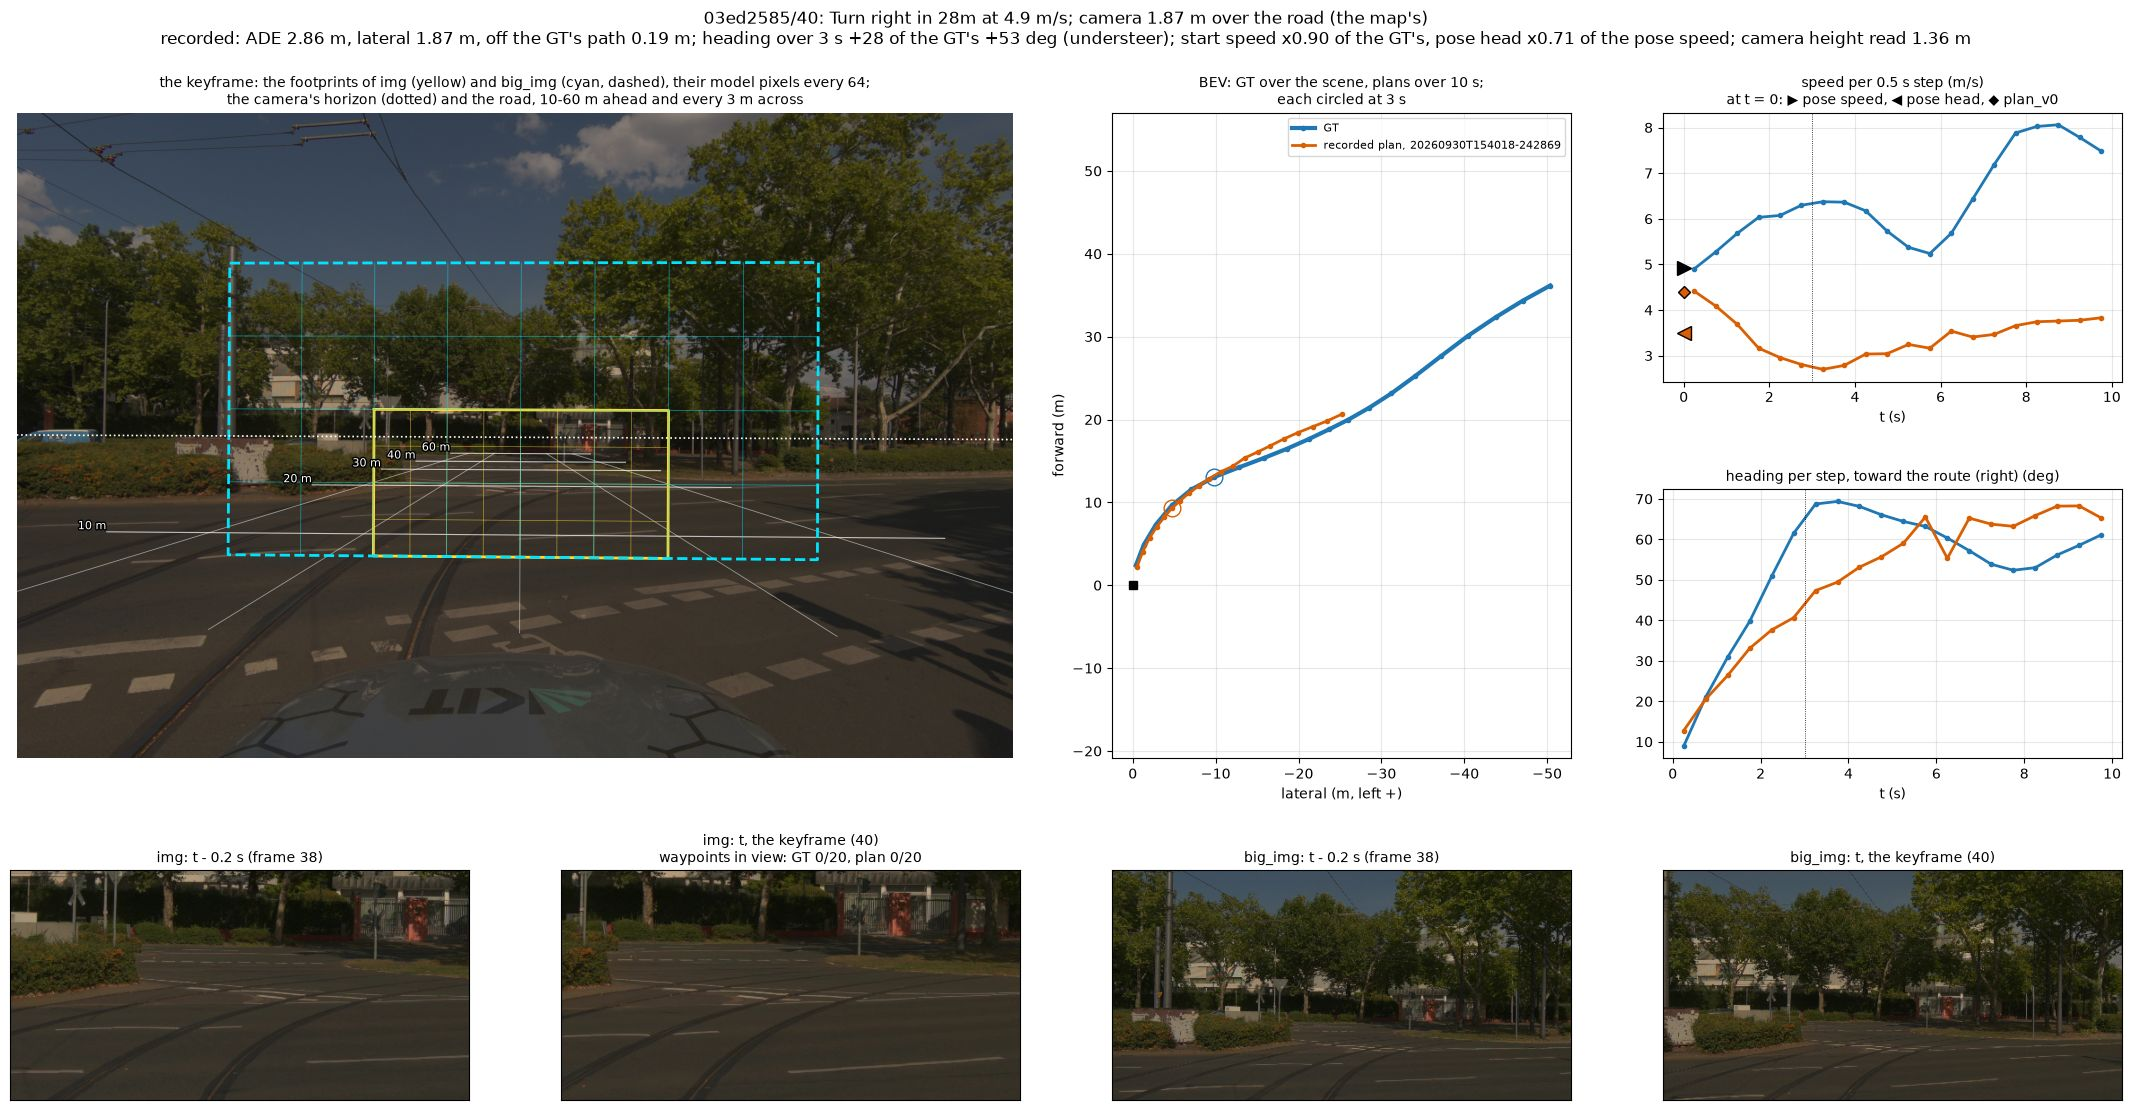

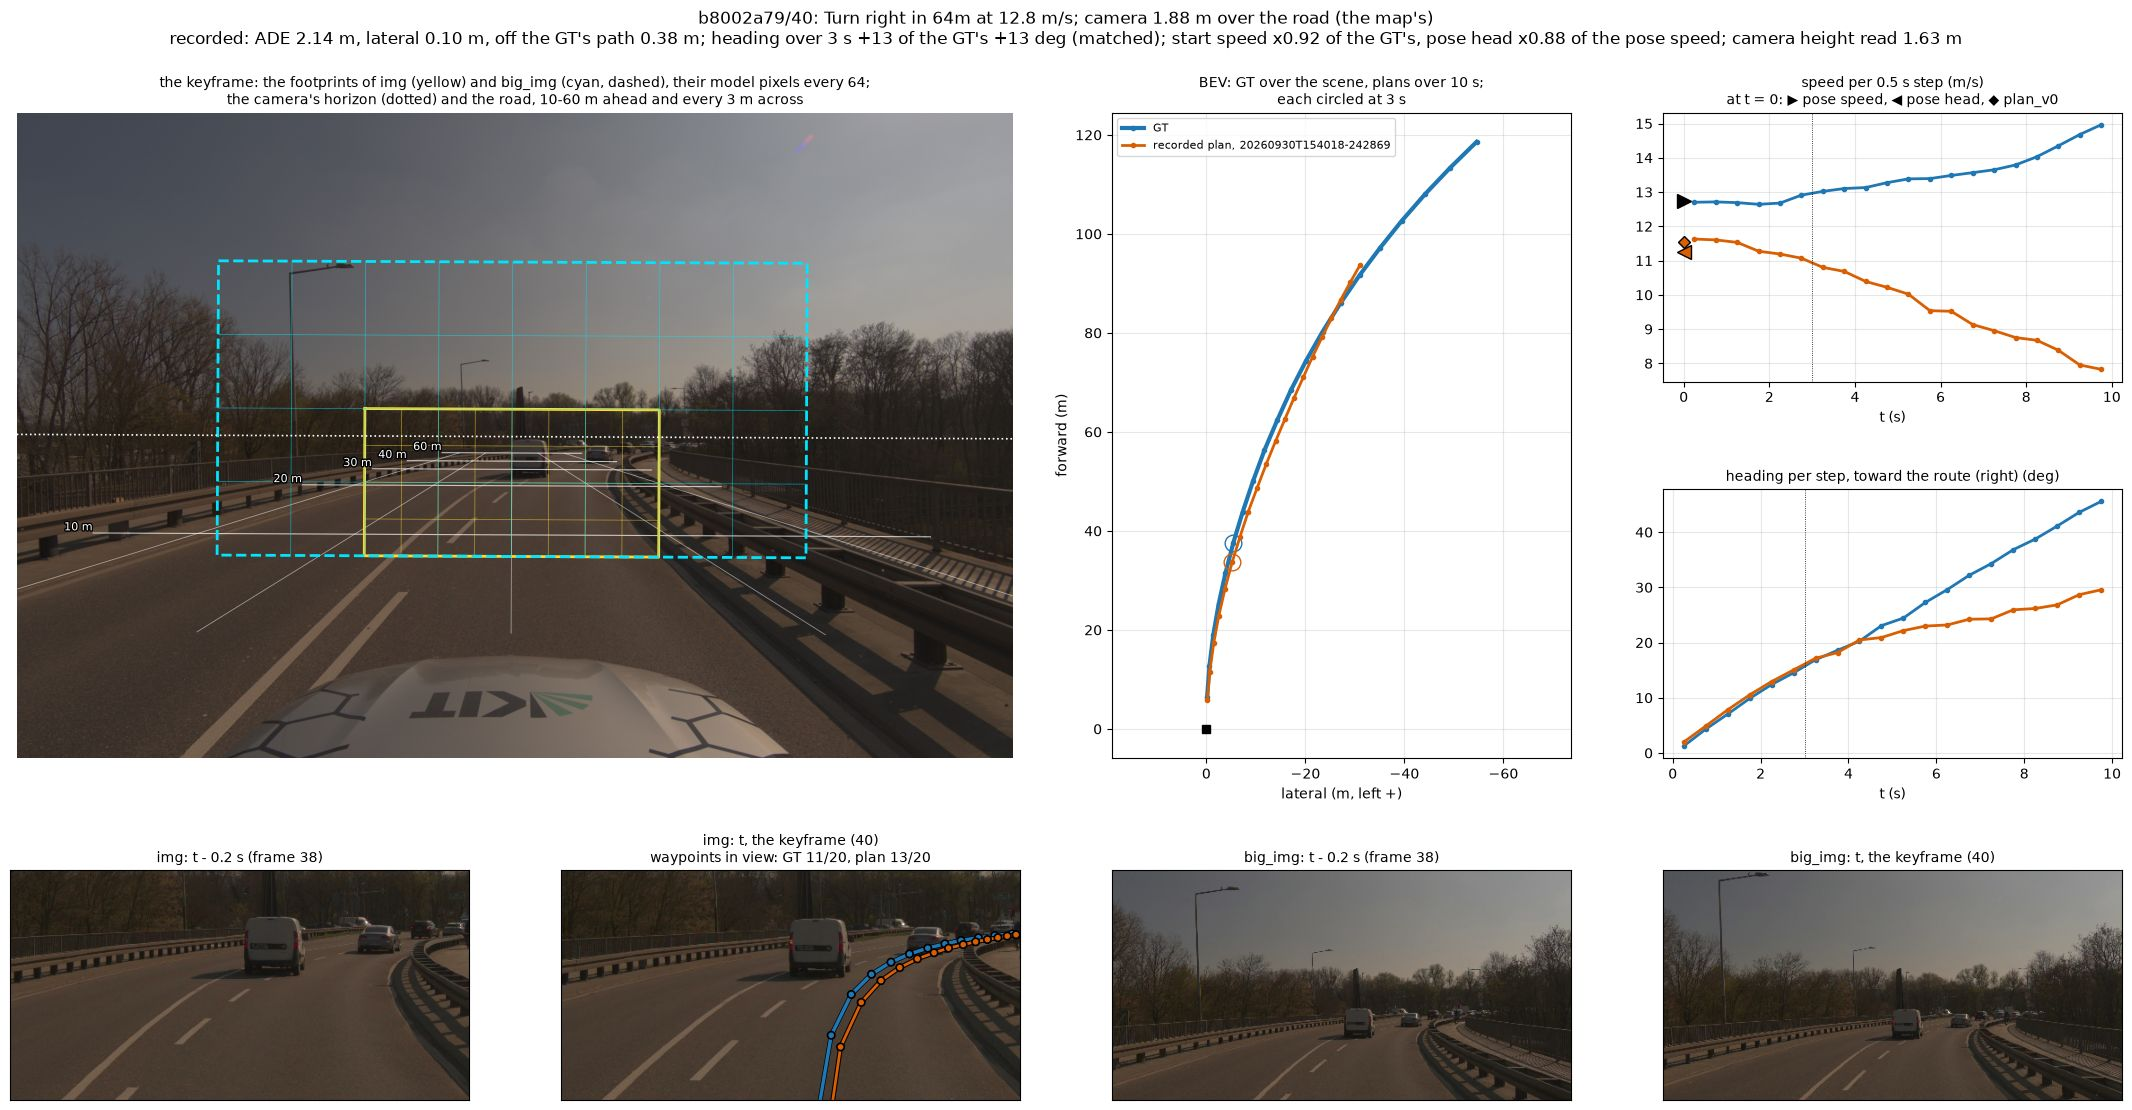

In [4]:
for key in lab.keys:
    lab.show_recorded(key, overlay=OVERLAY)

**How much of the path img sees.** Each view's title counts the waypoints inside it. On four of the five turns, img shows few or none of the GT's waypoints:
- at 4–5 m/s, roughly the first 2 s of the path are nearer than img's bottom edge, which meets the road about 8 m ahead;
- after that, the turn takes the path out of img's ±16°.

Only b8002a79/40 keeps its path inside img: 11 of its 20 GT waypoints, including 5 of the 6 within 3 s. That turn is at 12.8 m/s on a gentle bend.

To draw the path where it can be seen, set `OVERLAY = ("img", "big_img", "camera")`. big_img spans ±29° across, and the photo shows the camera's whole field of view.

### The warp and the homographies

The model never sees the camera's image directly. Each view is cut out of it by a 3 × 3 homography, one per view for each car:

`W[view] = camera_from_calib @ calib_from_model[view]`

- **`calib_from_model[view]`** is openpilot's own and is the same for every car. It maps a model pixel to a ray in the calibrated frame (x forward, y right, z down).
- **`camera_from_calib`** belongs to the car: the camera's intrinsics K, times its mounting rotation (the roll, pitch and yaw in calib.json).

So W contains a rotation and a focal change, but no camera height. The height enters through the road's homography into each view:

`inv(W[view]) @ G`, where `G = K @ [r1 r2 t]`

G maps a road point (x, y, 1) to a camera pixel, for a camera h metres above the road.

The cell below shows three things:
1. the matrices for `FOCUS`;
2. the road grid drawn through each view's homography, on all five turns;
3. a table of each turn's camera.

Part 3's image changes are applied between the two factors of W:

`camera_from_calib @ calib @ calib_from_model[view]`

dbba76d9/130, the stock warps and the road's homographies:

camera_from_calib: calibrated ray -> camera pixel (the camera's K, rotated by its rpy)
[[       1741        1840      -9.327]
 [       1140       7.433        1840]
 [          1  -0.0006502  -0.0006627]]

calib_from_model[img]: model pixel -> calibrated ray (openpilot's own; the same for every car)
[[  3.388e-21   4.665e-18           1]
 [   0.001099  -1.312e-18     -0.2813]
 [ -2.255e-20    0.001099    -0.05231]]

calib_from_model[big_img]: model pixel -> calibrated ray (openpilot's own; the same for every car)
[[  3.388e-21           0           1]
 [   0.002198          -0     -0.5626]
 [ -6.663e-20    0.002198     -0.3336]]

W[img] = camera_from_calib @ calib_from_model[img]: model pixel -> camera pixel
[[      2.022    -0.01025        1224]
 [   0.008168       2.022        1042]
 [ -7.145e-07  -7.282e-07           1]]

W[big_img] = camera_from_calib @ calib_from_model[big_img]: model pixel -> camera pixel
[[      4.044  

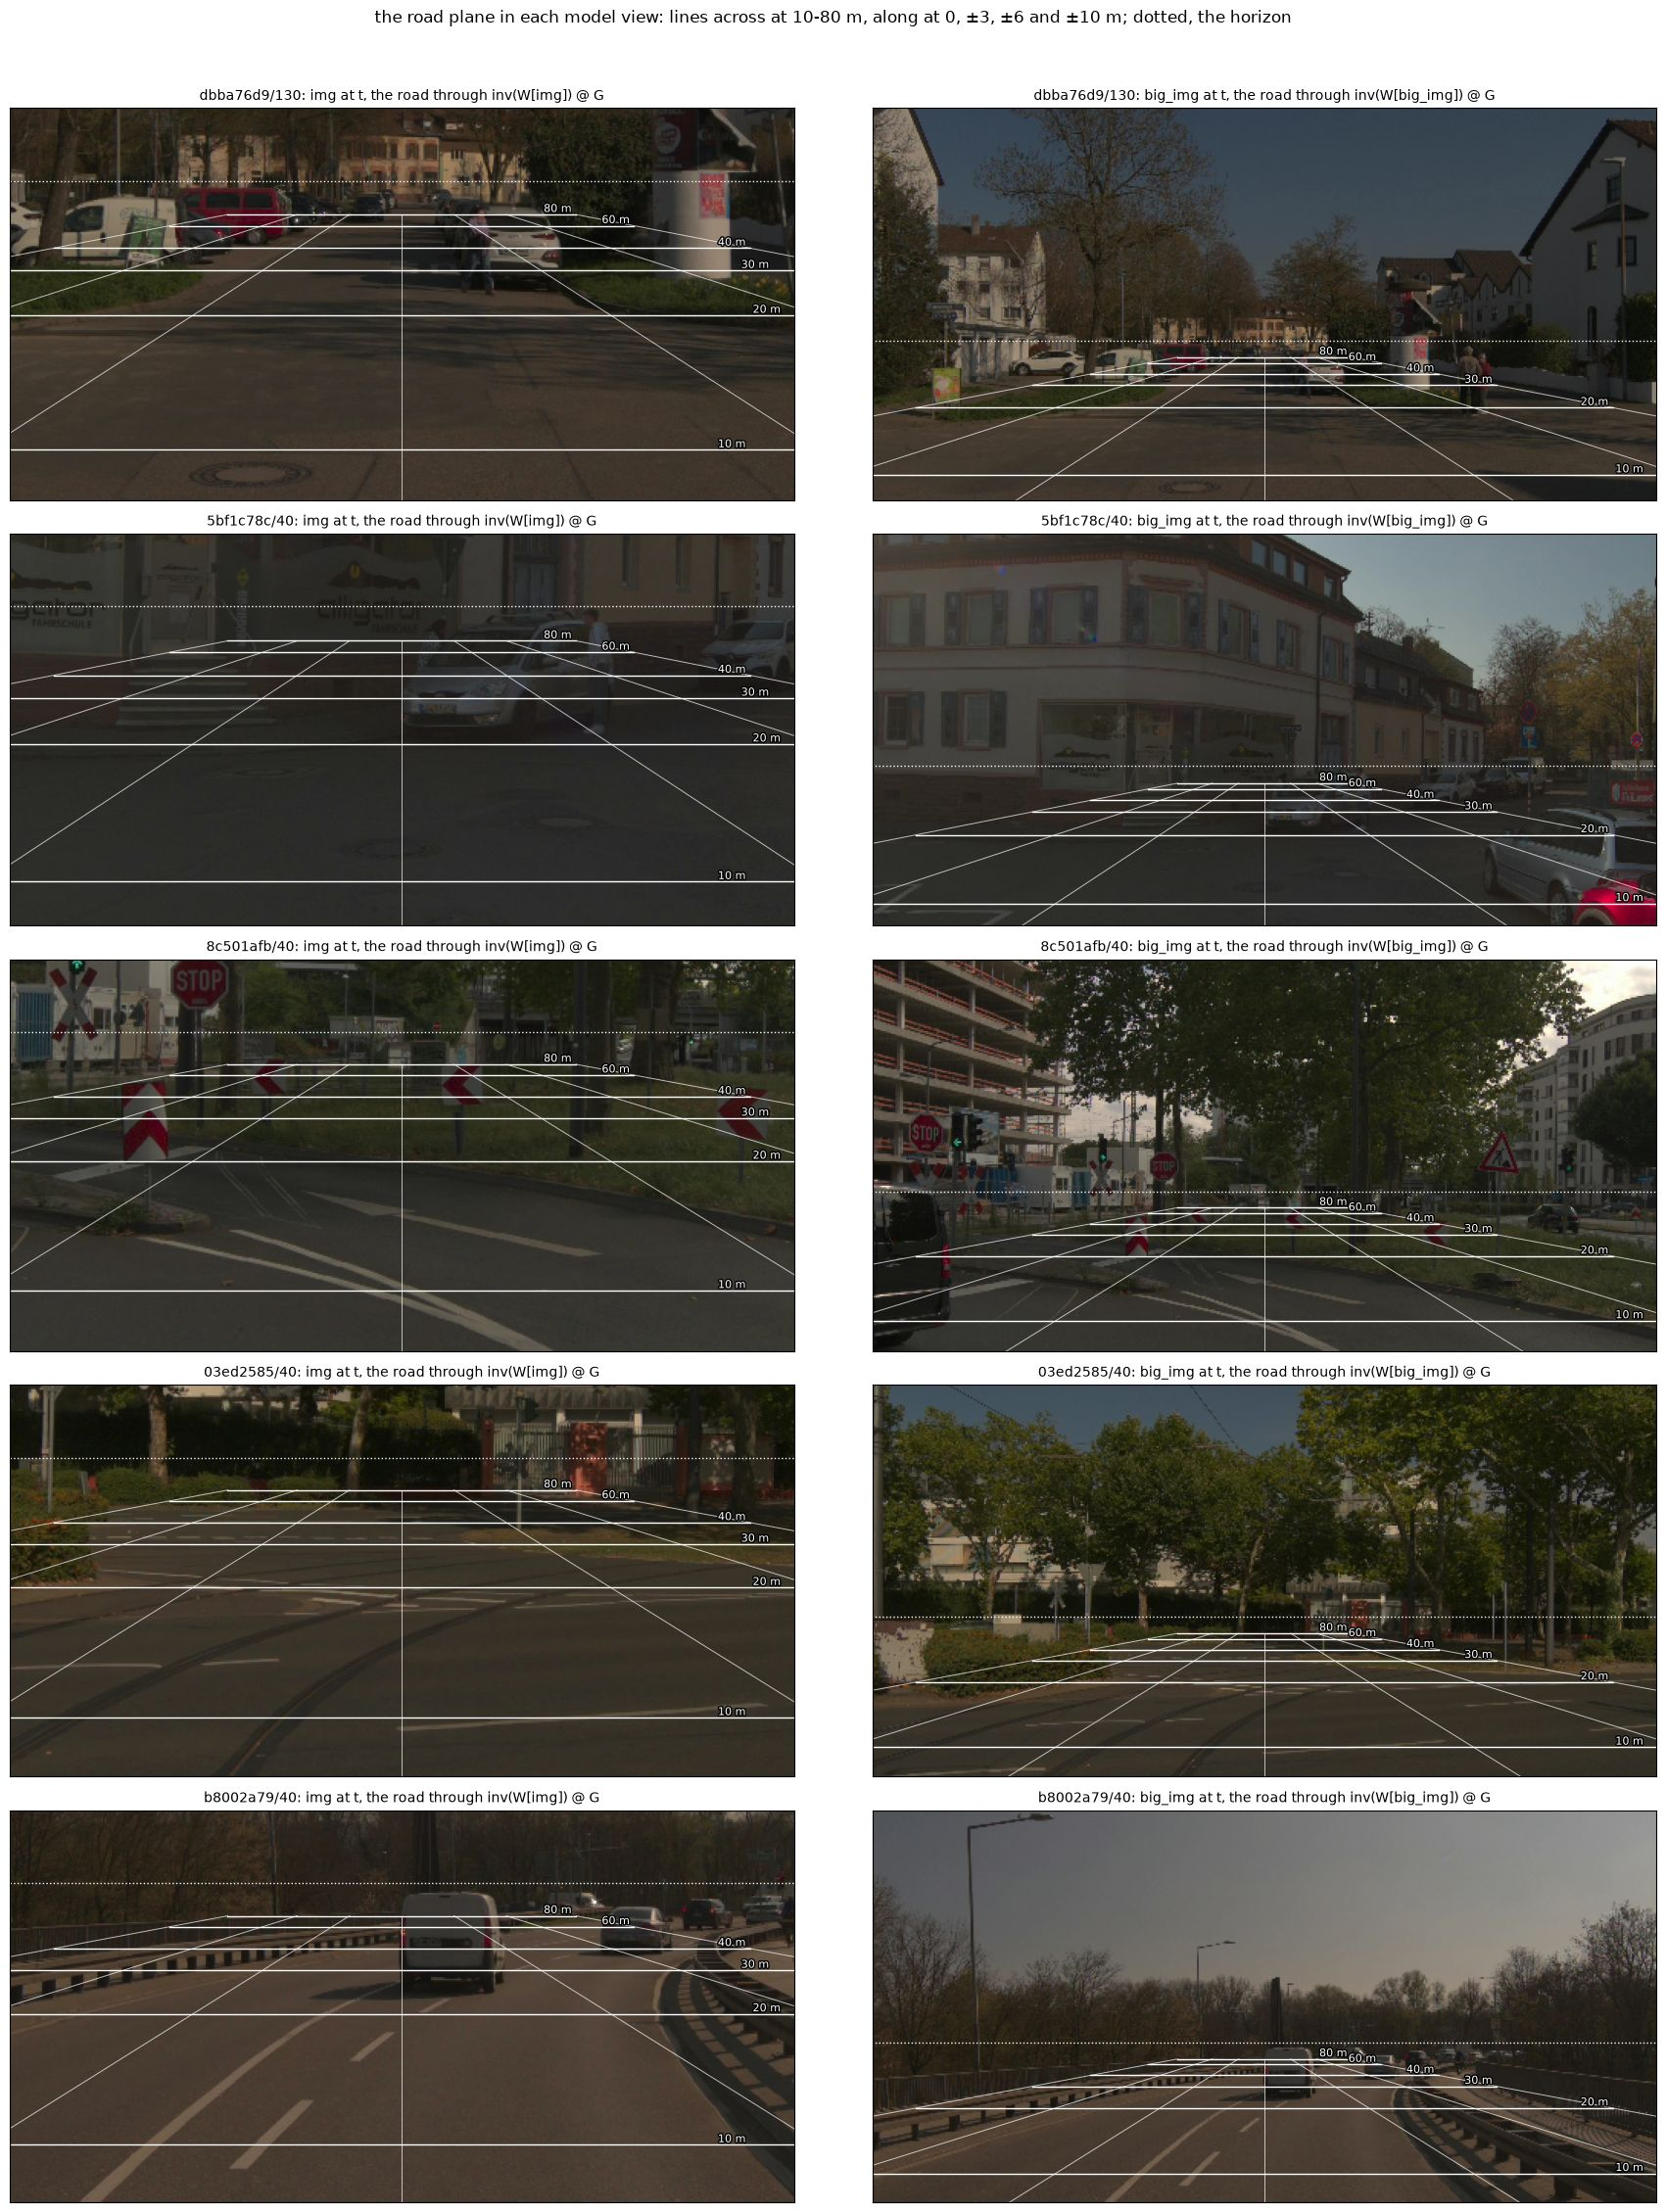

every camera's views span (right and down +): img -15.7 to +15.7 deg across, -3.0 to +12.9 down; big_img -29.4 to +29.4 deg across, -18.5 to +12.9 down


,"roll, pitch, yaw (deg)",focal length (px),img: camera px per model px,big_img: camera px per model px
key,,,,
dbba76d9/130,"+0.25, -0.04, +0.04",1841.0,2.02,4.05
5bf1c78c/40,"+0.25, -0.04, +0.04",1841.0,2.02,4.05
8c501afb/40,"+0.26, -0.11, +0.97",1841.0,2.02,4.05
03ed2585/40,"+0.26, -0.11, +0.97",1841.0,2.02,4.05
b8002a79/40,"+0.25, -0.04, +0.04",1841.0,2.02,4.05


In [7]:
lab.show_warps(FOCUS)

### The two front cameras, and comma's 65° cut

The car has two forward cameras, and a config can feed the model either (`camera`):
- **`"ring"`**, `camera_ring_front`: the stock adapter's, and every run so far.
- **`"base"`**, `camera_base_front_center`: a larger sensor behind a longer lens, mounted 0.20 m lower. It has 1.6 times as many camera pixels per degree, over a field of view as wide but less tall: 88° × 54°, against the ring camera's 87° × 63°.

Either way, openpilot cuts the same views from the camera through W, so the model sees the same scene. Three things change: the camera's height, its mounting angles, and how many camera pixels each model pixel is averaged from.

**comma's own camera** (the EON's) is 1164 × 874 px at a focal length of 910 px: 65.2° across. openpilot defines img at that focal length, so one img pixel is one EON pixel. `fov_deg=T.EON_FOV` cuts the camera frame to the EON's 65.2° about its centre, and by default resamples the cut to 1164 px across, as comma's camera would see it (dash-dot box). The model is told the cut's true focal length, so its views still show the same scene; what the cut changes is the sampling. Check 5 below confirms that, through the cut, every model pixel still lands on the same point of the scene.

The figure shows `FOCUS` from each camera: the keyframe with its views' footprints and the EON cut, then img and big_img at the keyframe. On each view:
- **solid white**: the row openpilot expects the horizon on. It is the row of the calibrated straight-ahead ray in openpilot's `calib_from_model`, 47.6 of 256 in img and 151.8 of 256 in big_img, the same for every car;
- **dashed white**: this camera's own horizon, through its calibration. With openpilot's warp the two coincide by construction, so here the dashed line hides under the solid one. In part 3, a `pitch_deg`, `roll_deg` or `fov_told_deg` moves it off.

The table gives each camera's frame, focal length, field of view, height, mounting angles, the camera pixels per model pixel in each view, and the camera pixels per EON pixel in the EON cut.

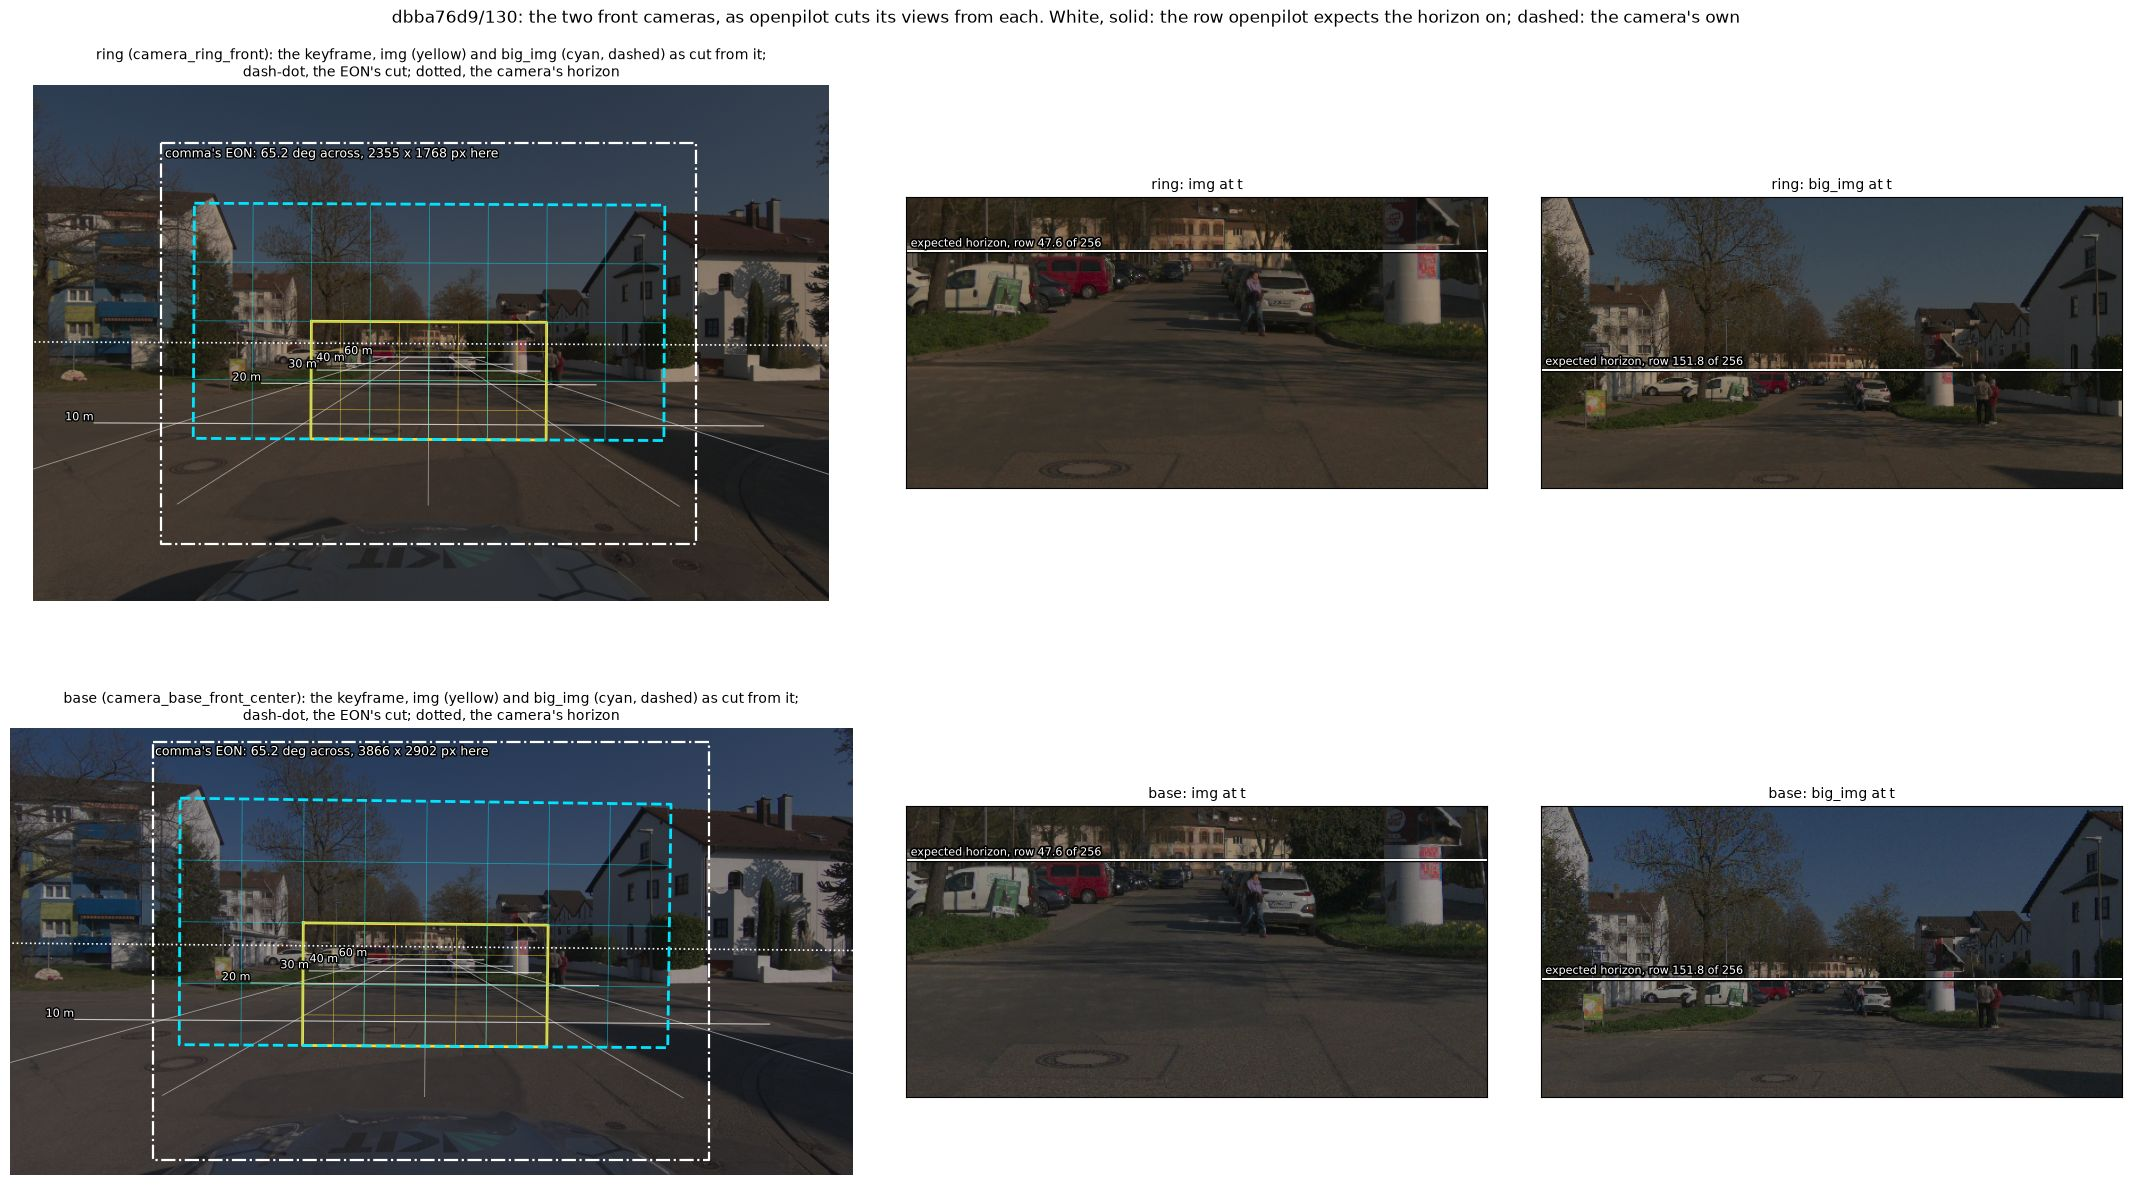

,frame (px),focal length (px),field of view (deg),height over the road (m),"roll, pitch, yaw (deg)",img: camera px per model px,big_img: camera px per model px,EON cut: camera px per EON px
camera,,,,,,,,
ring (camera_ring_front),3504 x 2272,1841.0,87.2 x 63.4,1.931,"+0.25, -0.04, +0.04",2.023,4.046,2.023
base (camera_base_front_center),5856 x 3104,3022.0,88.2 x 54.4,1.727,"+0.49, +0.51, -0.64",3.319,6.646,3.321


In [8]:
lab.show_cameras(FOCUS)

## 2 How the heights and speeds are measured, on one turn

`FOCUS`, 03ed2585/40, has the worst ADE of the five, and most of it is speed:
- The plan slows from 4.4 to 2.8 m/s while the car speeds up from 4.9 to 6.3 m/s (the figure's bottom right). By 3 s it has covered 10.6 m of the GT's 17.1 m.
- Covering less road, it has also turned less by 3 s: 28° of the GT's 53°, which the turn classes call understeer. Over the GT's whole length it turns as far as the GT does (`turn_frac` 1.01).
- On the way it keeps close to the GT's path: every waypoint within 3 s lies within 0.23 m of it.

The speed is robust; the exact path is not. Part 3's `noise` row shows what half-pixel shifts do to this plan: its start speed moves by 1% at most, but it can turn 9° more and move 0.42 m further from the GT's path.

The model also reads its camera as low: 1.36 m, where the map puts it at 1.87 m. Reading the camera too low and the car too slow go together, as below.

The model is told neither its height nor its speed. It reads both from the images, and two of its outputs show what it read:
- **`cam_h`**: the camera's height above the road plane, from supercombo's `road_transform` head;
- **the pose head**: the model's forward speed, from supercombo's `pose` head.

`plan_v0`, the plan's own start speed, is a separate output.

The tables below give every height and speed on this turn, with how each is measured. The figure shows how the two are linked:
- **Top row:** img's two frames, 0.2 s apart, and what changed between them. That change is all the image says about speed.
- **Bottom left:** the road 10–40 m ahead (green), and the image rows the model reads as those distances (red, dashed) at the height it reads. The plan is drawn twice: on the real road, and on the road the model reads.
    - **What geometry alone predicts** (argued). The model puts its camera at 1.36 m when it is 1.87 m up, so it reads every distance as 0.73 of the true one. It should therefore read the road between the frames as moving 0.73 as far, and so read 0.73 of the true speed.
    - **What was measured.** The pose head reads 0.71 here. Across keyframes, the note found that the speed goes as that ratio to the power 0.68, not 1.
- **Bottom right:** the speeds. The GT's and the plan's are plotted per 0.5 s step, with the readings at t = 0.

**dbba76d9/130: Turn left in 18m at 3.9 m/s; camera 1.93 m over the road (the map's).** From the recorded run, 20260930T154018-242869.

**The camera's height over the road (m)**

| height | m | how it is measured |
|---|---|---|
| the harness's | 1.997 | calib.json's camera z in the rig's base frame, plus `POD_HEIGHT_M` = 2.2 m, a fixed guess at the base frame's height over the road (`_read_calibration`). openpilot never reads it: its warp is a rotation, and has no height in it. |
| the map's | 1.931 | scenario mining's `height_ring_front_m`: on each of the scene's frames on the map, the front camera's height over the Lanelet2 road surface beneath it, from the INS pose; then the median over those frames. This is the real height the notebook draws the road at. |
| **the model's** (`cam_h`) | **1.413** | `extras.road.camera_height`: the z of supercombo's `road_transform` head, where it puts the road plane below the camera, on the keyframe's tick. Nothing the model is given holds a height: it infers this from the images. |
| openpilot's own | 1.22 | comma's camera over the road, the height supercombo was trained at. |

**The speeds at t = 0 (m/s)**

| speed | m/s | how it is measured |
|---|---|---|
| ▶ **the pose speed** | **3.87** | `loader.ego_speed`: \|p(k+1) − p(k−1)\| / 0.2 s, the INS poses at 10 Hz either side of the keyframe k = 130. The right speed. |
| the pose speed over `img`'s pair | 4.01 | \|p(k) − p(k−2)\| / 0.2 s, between exactly the two frames `img` holds, 128 and 130. |
| the GT's first step | 3.84 | \|GT(0.5 s)\| / 0.5 s: where the poses put the car half a second on. |
| ◀ **the pose head** | **3.46** | `extras.pose.velocity[0]`: the forward speed from supercombo's `pose` head, on the keyframe's tick. Nothing the model is given holds a speed: it reads its motion from the images (`img` and `big_img` each hold two frames 0.2 s apart) and from its own features of earlier ticks. |
| ◆ `plan_v0` | 3.35 | `extras.plan_v0`: the plan's own velocity at t = 0, a separate output from the pose head. It is the one openpilot's longitudinal control reads. |
| the plan's first step | 3.06 | \|plan(0.5 s)\| / 0.5 s: what the score sees. |

**Ratios**

| ratio | this turn | for reference |
|---|---|---|
| `head_ratio` = ◀ / ▶ | **0.896** | 0.877 is the note's median over 205 keyframes: 0.817 where the model reads its height low (near 1.39 m), 0.915 where it reads it high (near 1.62 m). |
| `v0_ratio` = the plan's first step / the GT's | 0.798 | median 0.909 |
| ◆ / ◀ | 0.967 | median 1.024: the plan starts at about the speed the pose head reads. |
| the model's height / the map's | 0.732 | where `head_ratio` would be if the model measured distance by geometry alone: a road point X ahead is read at X · cam_h / h. |
| (the model's height / the map's)^0.68 | 0.809 | where the note's fit across keyframes puts it (exponent CI 0.62–0.75): the speed is misread less than the height. |

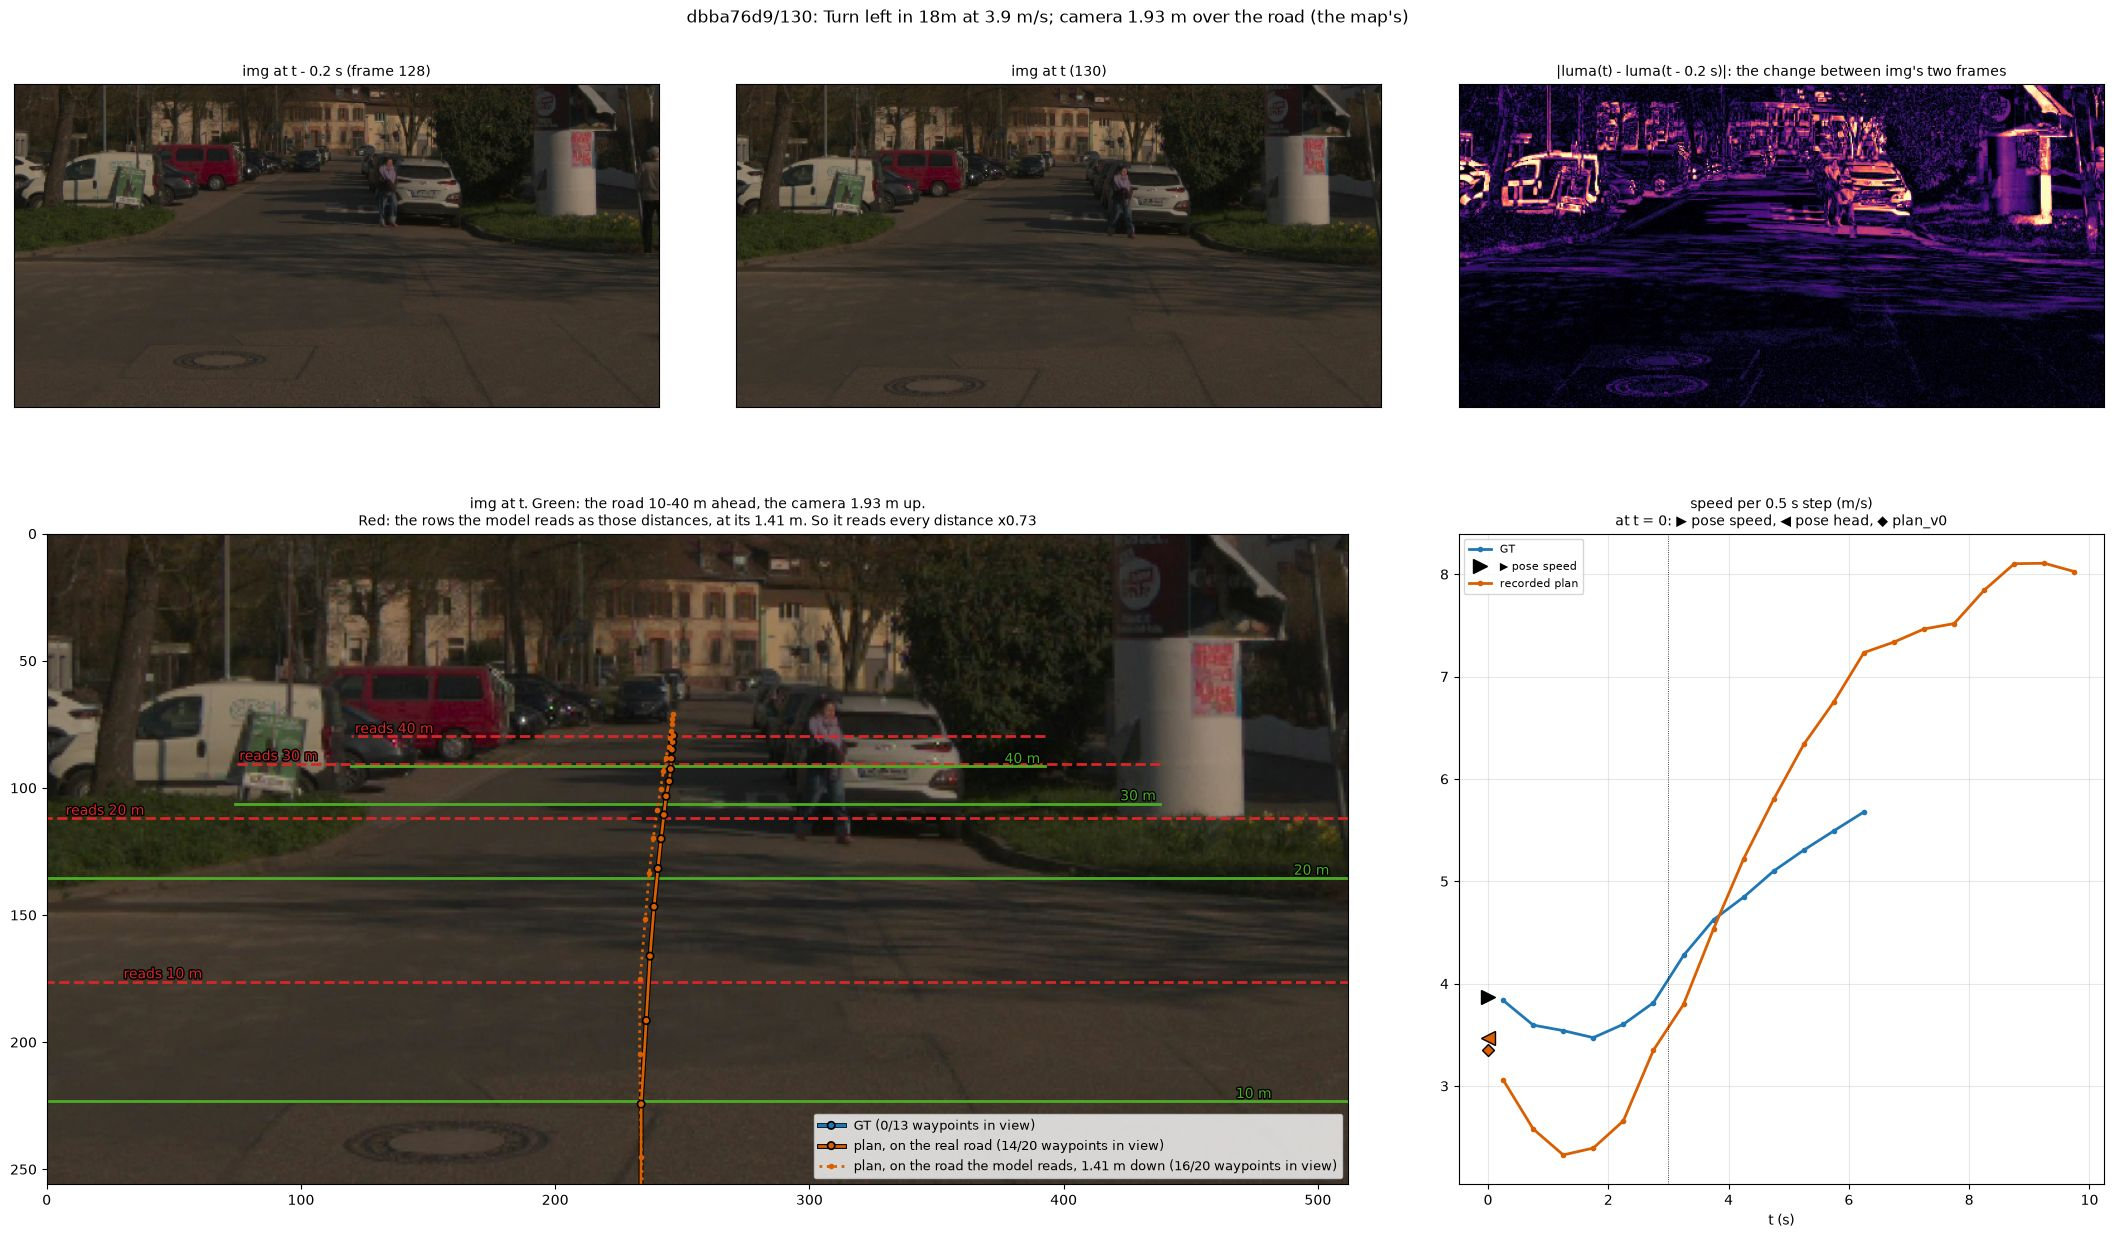

In [9]:
lab.show_measurements(FOCUS)

## Before part 3: does the node give the stock model's output?

Five checks, each of which raises an error if it fails:
1. **The node is the stock adapter.** With no config, the node gives the same plan, extras, warps and ticks as the untouched adapter, bit for bit. So does an identity config sent the way every config is sent, as `calib` and `post` matrices. So a change in the plan is the config's own, and the half-pixel shifts behind the `noise` row and part 4's floor measure the shift alone.
2. **The drawings show what the model was fed.** What this notebook draws as the model's input matches what the model received. This is checked on every path the node has: shift, supersampling, filter, tone tables and blanking.
3. **Stock run here reproduces the recorded run** on every turn, within 0.25 m over 3 s. The recorded run was made on a GPU, so the match cannot be bit for bit.
4. **The tick counts agree.** The model ticks counted here are the node's own. img's older frame is found from them.
5. **A cut does not move the views.** For the EON cut (`fov_deg=T.EON_FOV`), the warp openpilot computes from the cut's intrinsics equals the stock warp followed by the map from camera pixels to cut pixels, to within 0.01 cut px over a grid on each view. The mounting angles openpilot derives are unchanged. So a cut changes which pixels the views are sampled from, not where they look.

In [10]:
lab.checks(FOCUS)

started 1 node(s) on cpu in 3 s
1. dbba76d9/130: the node with no config, against the untouched adapter, the same: {'plan': True, 'extras': True, 'warps': True, 'ticks': True}
1. dbba76d9/130: the node with an identity config, sent as configs are, against the untouched adapter, the same: {'plan': True, 'extras': True, 'warps': True, 'ticks': True}
ran 1 on 1 node(s) in 1 s (median 0.8 s each)
2. dbba76d9/130, stock, img: drawn == fed: True
2. dbba76d9/130, stock, big_img: drawn == fed: True
ran 1 on 1 node(s) in 1 s (median 1.0 s each)
2. dbba76d9/130, dx_px=0.5 supersample=3 sharpen=0.5 gamma=0.8 saturation=1.3 blank=img, img: drawn == fed: True
2. dbba76d9/130, dx_px=0.5 supersample=3 sharpen=0.5 gamma=0.8 saturation=1.3 blank=img, big_img: drawn == fed: True
3 and 4. stock, run here on cpu, against 20260930T154018-242869, recorded on a GPU:


,largest difference within 3 s (m),over 10 s (m),ADE here - recorded (m),"ticks, node","ticks, counted here",img's older frame
key,,,,,,
dbba76d9/130,0.006,0.031,0.000,98,98,128 (observation -3)
5bf1c78c/40,0.010,0.055,-0.006,90,90,38 (observation -3)
8c501afb/40,0.016,0.044,0.001,90,90,38 (observation -3)
03ed2585/40,0.016,0.062,0.006,90,90,38 (observation -3)
b8002a79/40,0.016,0.125,-0.006,90,90,38 (observation -3)


5. dbba76d9/130, img: the 65.2 deg cut (1164 x 874, 2.023 camera px each) sees every model pixel where the recorded frame does, to 0.0000 cut px; rpy the same: True
5. dbba76d9/130, big_img: the 65.2 deg cut (1164 x 874, 2.023 camera px each) sees every model pixel where the recorded frame does, to 0.0001 cut px; rpy the same: True


## 3 Change the image, the camera or the intent, on one turn

Edit `CONFIG` and run the cell. The model plans `FOCUS` again with the image changed, and the figure shows the result beside stock:
- **Top row:**
    - the keyframe, with stock's view outlines (grey) and the config's;
    - the road grid as the config shows it to the model (red), against where it really is (grey);
    - the paths seen from above.
- **Middle row:** the speed and the heading at each 0.5 s step.
- **Bottom rows:** the four images the model is given, stock's above the config's.
    - On the `OVERLAY` views, the GT and the plan are drawn.
    - Two horizons are drawn on each keyframe view: the row openpilot expects the horizon on (solid white, labelled: row 47.6 of img's 256, 151.8 of big_img's), and where the camera's own horizon lands in the view the config makes (dashed). Stock puts them together; a config that pitches, rolls or mis-tells the field of view pulls them apart.

The table under the figure gives part 1's metrics for stock, for the config, and the change between them. Its last row, **`noise`**, is the largest change that any of eight half-pixel shifts (`T.SHIFTS`) makes on this turn, with every turn class they give.
- The shifts move the geometry by almost nothing, so a change within `noise` is not the config's doing.
- They take eight runs the first time on each turn, cached after that. `lab.tweak(..., noise=False)` skips them.

**How to use it**
- Every value in `CONFIG` below leaves the image unchanged, and the knobs combine freely.
- Set **`RUN_MODEL = False`** to draw only what the model would be shown, in a second or two, without running the model.
- To run another turn, use `lab.tweak(key, CONFIG)` with any key.
- **`AGAINST`** sets the baseline the config is drawn and scored beside: `None` is stock, or give another config. For example, to see what intent does on the base camera, set `CONFIG = dict(camera="base", desire="turn")` and `AGAINST = dict(camera="base")`. The `noise` row then shifts the baseline, not stock.

| knob | what the model is shown | what it should do to the plan |
|---|---|---|
| `height_scale` s | the road as seen from a camera at h / s | every distance and width s× larger, so faster |
| `zoom` k | the image magnified k×, like a longer lens | distances ×1/k with widths unchanged, so slower when k > 1; a smaller field of view |
| `hstretch` g | the image stretched g× sideways | lateral offsets and lane widths ×g; curves look tighter |
| `yaw_deg` ψ | the view turned ψ left | the plan's heading turns ψ right |
| `turn_yaw_deg` | the view turned toward the route's side; negative turns it away | turned toward: the plan turns away from the route; turned away: the plan turns toward it |
| `pitch_deg` | the view tilted up, so the road sits lower | the road reads nearer, so slower |
| `roll_deg` | the view rolled, so the right side looks lower | the plan drifts sideways |
| `ahead_m`, `left_m` | the camera moved over the road, at the same height | the plan starts where that camera would stand |
| `dx_px`, `dy_px` | the sampling grid moved right and down, in model pixels | nothing beyond noise; half a pixel is the noise floor |
| `views` | which views the geometry applies to: `"both"`, `"img"` or `"big_img"` | |
| `supersample` n, `ss_views` | each model pixel the mean of n × n camera samples, in `ss_views` | big_img spans about 4 camera pixels per model pixel here, against 1.25 on comma's camera |
| `sharpen` α | an unsharp mask, δ + α(δ − blur) over 3 × 3; −1 is the blur itself | |
| `gamma`, `contrast`, `brightness`, `saturation` | tone, on both views: gamma on luma (below 1 is brighter); contrast about mid-grey; brightness in luma steps; saturation 0 is grey | |
| `blank` | `"img"` or `"big_img"` shown as flat grey | shows what that view contributes |
| **the source** | | |
| `camera` | `"ring"` (stock) or `"base"`: the same views, cut from the other front camera (part 1) | openpilot builds the warp from the base camera's own intrinsics and mounting, as it does from the ring camera's. The base camera is 0.20 m lower and has 1.6× the pixels per degree |
| `fov_deg` θ | the frame cut to θ° across about its centre before openpilot sees it; `T.EON_FOV` (65.2) is comma's camera; 0 is the frame as recorded | at 65.2° the views still fit and look at the same scene, sampled through the cut's pixels. Under about 58° (big_img spans ±29°), big_img reaches past the cut's edge. Once the model has run, the line under the table gives each view's share inside the frame it was fed |
| `fov_aspect` | the cut's width over its height; the EON's 1164 / 874 by default | a cut too tall for the frame raises an error that says so |
| `fov_width` w | the cut resampled to w px across; the EON's 1164 by default. 0 crops whole camera pixels and resamples nothing | how coarsely the cut is sampled before openpilot warps it |
| `fov_filter` | the resampling filter: `"area"` (the box mean, as a sensor bins), `"bilinear"`, `"lanczos"` or `"nearest"` | |
| `fov_told_deg` | the model told the cut is this many degrees across, not its true width; 0 tells it the truth | openpilot computes its warp from the wrong focal length, so the views are magnified by about tan(told / 2) / tan(θ / 2) about the centre, as `zoom` does; told wider is a longer lens |
| **the intent** | | |
| `desire` | `"off"` (stock: every frame sent STRAIGHT, as the recorded run sent); `"turn"`: the route's side as openpilot's `turnLeft` / `turnRight`; `"lane_change"`: as `laneChangeLeft` / `laneChangeRight`, in distribution but a different manoeuvre, so a control for `"turn"` | `p_turn` shows whether the model takes it up |
| `desire_lead_s` | how long before the keyframe the desire starts, 0 to 4.8 s | openpilot pulses a desire once, on its first frame, and its queue holds it for 5 s, so the model sees it at the keyframe in every case; the lead sets how long it has had it |

**Where to start.** These numbers come from [the note](openpilot_drv_supcombo_kitscenes_four_questions.md), measured on other keyframes:
- **Speed.**
    - On average, the pose head reads the car's speed correctly at `height_scale` 1.22 (CI 1.17–1.26), and the plan's first step matches the GT's at 1.18 (1.12–1.22).
    - Both respond less than the image changes: the head as s^0.54, the plan's first step as s^0.56.
    - This turn is in the low mode (its road head reads the camera at 1.36 m), where they respond as s^0.71 and s^0.65.
    - On this turn the two readings need different scales. The head reads 0.71 of the car's speed, but the plan starts at 0.90 of the GT's (part 2). By the low-mode exponents:
        - the plan's start would be right near s ≈ (1 / 0.90)^(1 / 0.65) ≈ 1.18;
        - the head would be right near s ≈ (1 / 0.71)^(1 / 0.71) ≈ 1.6. That is past the sweep's largest scale, 1.53, so treat 1.6 as a direction, not a value.
    - The score sees the plan, not the head. And this plan's trouble is that it slows over 3 s, so a scale that fixes its start may not fix its speed at 3 s.
- **This turn's shape is sensitive to the pixels.** All eight shifts turn its plan more than stock does, by 0.7–8.9° over 3 s. So stock sits at the low end of what the model does with this image, and a config that turns this plan a few degrees more may only be doing what any change does. Part 4 tests it on all five turns.
- **`zoom` changes distance only.** `zoom` 0.9 changes distances as `height_scale` 1.11 does, but leaves widths as they are.
- **Turning.** Across 95 image settings on ten turns, at most one more plan turned toward the route. An image change fixes the speed; it may not fix the turn.

ran 1 on 1 node(s) in 1 s (median 0.8 s each)


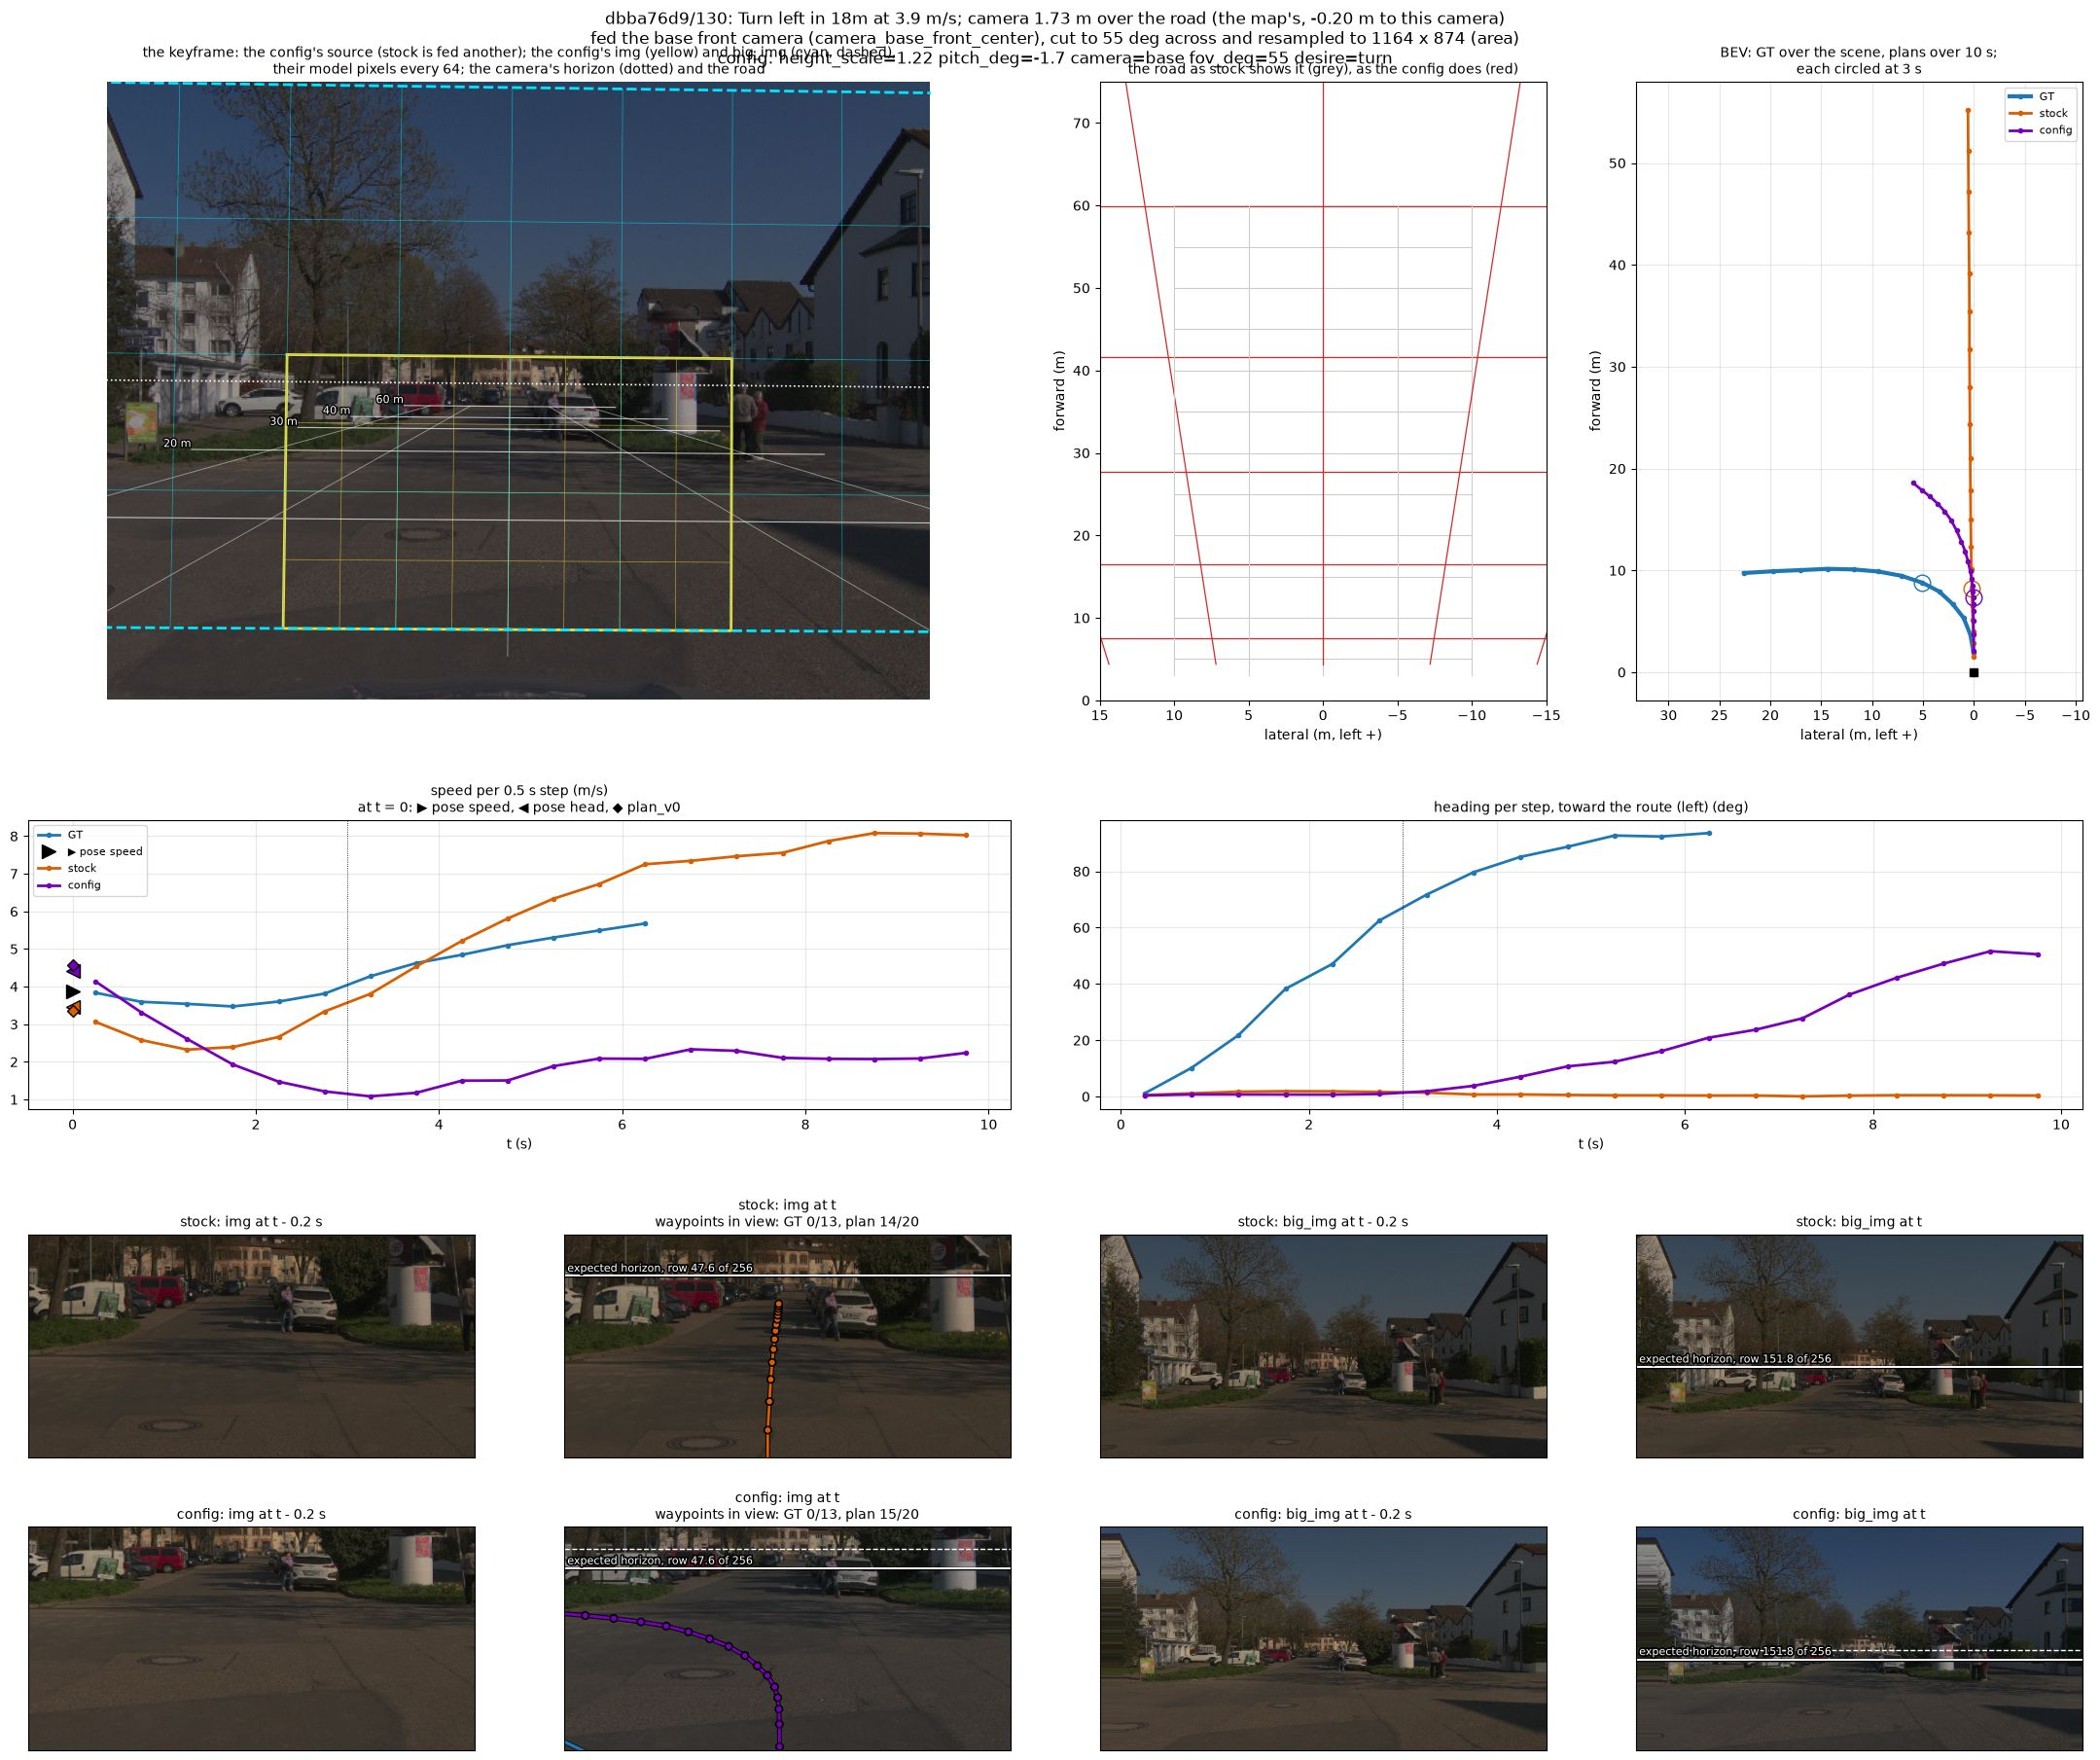

,mode,ade,ade_long,lat,lon,path_err,dpsi,gt_dpsi,dpsi_err,turn_frac,speed_rmse,v0_ratio,head_ratio,plan_v0,cam_h,p_turn
stock,not_planned,2.318,10.123,1.896,1.026,0.850,1.103,61.474,-60.371,-0.002,0.948,0.798,0.896,3.352,1.413,0.001
config,understeer,2.062,8.584,1.943,0.641,0.978,0.519,61.474,-60.955,0.222,1.566,1.079,1.142,4.566,1.387,1.000
change,not_planned -> understeer,-0.256,-1.539,0.047,-0.385,0.128,-0.584,0.000,-0.584,0.223,0.618,0.280,0.246,1.215,-0.026,0.999
noise,not_planned,0.068,0.141,0.024,0.152,0.078,0.384,0.000,0.384,0.001,0.076,0.026,0.028,0.076,0.011,0.000


noise: the largest change that any of the 8 half-pixel shifts (T.SHIFTS) of stock makes on this turn, and every class they give; a change within it is not the config's doing
the config shows a road point (X, Y) about where stock shows (X x 2.083, Y x 2.078), measured 20 m ahead; share of each view inside the camera frame: img 1.00, big_img 0.93


In [18]:
CONFIG = dict(
    # geometry
    height_scale=1.22,  # s: the road as from a camera at h / s
    zoom=1.0,  # k: magnified k x
    hstretch=1.0,  # g: stretched g x sideways
    yaw_deg=0.0,  # the view turned left (deg)
    turn_yaw_deg=0.0,  # the view turned toward the route's side (deg); negative is away
    pitch_deg=-1.7,  # the view tilted up (deg)
    roll_deg=0.0,  # the view rolled, its right side down (deg)
    ahead_m=0.0,  # the camera moved forward (m)
    left_m=0.0,  # and left (m)
    dx_px=0.0,  # the sampling grid moved right (model pixels)
    dy_px=0.0,  # 30.0,  # and down
    views="both",  # where the geometry applies: "both", "img" or "big_img"
    # sampling
    supersample=1,  # n: n x n camera samples per model pixel
    ss_views="big_img",  # where supersampling applies
    sharpen=0.0,  # alpha; -1 is a 3 x 3 blur
    # tone, on both views
    gamma=1.0,  # on luma; under 1 is brighter
    contrast=1.0,  # about mid-grey
    brightness=0.0,  # luma steps
    saturation=1.0,  # 0 is grey
    # ablation
    blank="",  # "img" or "big_img": that view shown as flat grey
    # the source
    camera="base",  # "ring" (stock) or "base"
    fov_deg=55.0,  # cut the frame to this many degrees across; T.EON_FOV is comma's 65.2; 0 is as recorded
    fov_aspect=T.EON_W / T.EON_H,  # the cut's width over height
    fov_width=T.EON_W,  # resample the cut to this many px across; 0 crops whole pixels
    fov_filter="area",  # "area", "bilinear", "lanczos" or "nearest"
    fov_told_deg=0.0,  # tell the model the cut is this wide (deg); 0 tells it the truth
    # the intent
    desire="turn",  # "off", "turn" or "lane_change"
    desire_lead_s=0.0,  # the desire starts this long before the keyframe (s), 0 to 4.8
)
AGAINST = None  # the baseline: None is stock, or a config such as dict(camera="base")
RUN_MODEL = True  # False: draw what the model would be shown, without running it

lab.tweak(FOCUS, CONFIG, run=RUN_MODEL, overlay=OVERLAY, against=AGAINST)

## 4 The config on all five turns

Run this once part 3's config looks worth scoring. It plans the five turns twice, with `CONFIG` and with part 3's `AGAINST` (stock when it is `None`), both here. It shows:

1. **Each turn**, stock and config side by side, with the change. The columns are part 1's. `dpsi_err` is the plan's heading change over 3 s minus the GT's; it is negative when the plan turns too little.
2. **The means over the turns, with a verdict for each criterion.** Lower is better for every criterion except the count of plans that turn toward the route:

    | group | criteria |
    |---|---|
    | ADE | ADE over 3 s (the benchmark's score); ADE over the GT's whole length, up to 10 s |
    | alignment | lateral error over 3 s; distance from the GT's path over 3 s; heading error over 3 s; how many plans turn toward the route (higher is better) |
    | speed profile | RMSE of the 0.5 s step speeds over 3 s; how far the plan's start speed is from the GT's; how far the pose head's speed is from the pose speed |


    Two rows follow without a verdict: how many plans turn toward the route, and the mean `p_turn`.
3. **One verdict per group**: better, worse, mixed, or no clear change.
4. **Each turn drawn**: the paths, the speeds and the headings. Stock is orange; the config is purple.

**Read alignment with the speed profile.** The lateral and heading errors compare the plan and the GT at the same time, as the benchmark does, so a plan that is only too slow on a curve shows both. The distance from the GT's path ignores timing. In part 1's table:
- 03ed2585/40 keeps to the GT's path (`path_err` 0.19 m) but is slow, so its lateral error is 1.87 m;
- b8002a79/40 is about a tenth slower than the GT, but its sideways offset keeps pace with the GT's (`lat` 0.10 m). It reaches each offset in less distance, so it curves more tightly than the road (`path_err` 0.38 m).

**The noise floor.** Any change at all to the image moves every score a little. So a change counts only when it is bigger than what eight shifts of half a model pixel do (`T.SHIFTS`); those shifts move the geometry by almost nothing.
- **Each turn:** a turn counts as better or worse when its change exceeds the median change a shift makes on one turn.
- **The mean:** the verdict is better when the mean change exceeds the largest change any shift makes to the mean, and more turns get better than worse. Worse is the same in reverse.
- **Each group:** better when one of its criteria is better and none is worse; mixed when some are better and some worse.
- `lab.compare(CONFIG, noise=False)` counts any change at all.

The first call runs the shifts on the five turns: 40 runs, cached after that. With `AGAINST` set, the shifts are of that baseline, so they run again for each new baseline.

Five turns is a small sample. A clear verdict here is a reason to test on more turns, not a result. `SCENES` accepts any KITScenes keyframe.

staged 41 frame(s) of 5bf1c78c/40's cut in 1 s
staged 41 frame(s) of 8c501afb/40's cut in 2 s
staged 41 frame(s) of 03ed2585/40's cut in 2 s
staged 41 frame(s) of b8002a79/40's cut in 1 s
started 4 node(s) on cpu in 3 s
ran 4 on 4 node(s) in 1 s (median 1.0 s each)


**Each turn, stock and config: dy_px=20 camera=base fov_deg=55 desire=turn** (both run here on cpu)

ade               ade_long                    lat         \
              stock config change    stock  config  change  stock config   
dbba76d9/130  2.318  2.170 -0.148   10.123   8.318  -1.805  1.896  1.960   
5bf1c78c/40   1.710  1.122 -0.588   15.582   8.806  -6.775  0.857  0.949   
8c501afb/40   0.744  2.313  1.569   15.484  19.695   4.212  0.464  1.979   
03ed2585/40   2.864  1.578 -1.286   13.517   9.250  -4.267  1.870  1.470   
b8002a79/40   2.132  4.179  2.047   12.607  27.130  14.523  0.098  0.352   

                    path_err               dpsi_err                 turn_frac  \
             change    stock config change    stock  config  change     stock   
dbba76d9/130  0.064    0.850  0.879  0.028  -60.371 -61.106  -0.735    -0.002   
5bf1c78c/40   0.092    0.336  1.063  0.728  -38.391 -29.886   8.505    -0.957   
8c501afb/40   1.515    0.250  1.986  1.735  -21.619 -47.347 -25.728     0.371   
03ed2585/40  -0.400    0.200  0.573  0.373  -24.608 -23.142   1.466     1.004   
b8002a79/40   0.254    0.383  0.462  0.078   -0.113   2.384   2.497     0.614   

                           speed_rmse               v0_ratio                \
             config change      stock config change    stock config change   
dbba76d9/130  0.414  0.415      0.948  1.439  0.491    0.798  0.967  0.168   
5bf1c78c/40   1.190  2.146      1.221  0.384 -0.836    0.805  1.028  0.222   
8c501afb/40   0.406  0.035      0.413  0.273 -0.140    0.792  0.882  0.091   
03ed2585/40   0.903 -0.101      2.443  1.567 -0.876    0.898  1.095  0.196   
b8002a79/40   1.440  0.826      1.368  3.094  1.726    0.916  0.882 -0.033   

             head_ratio                cam_h               p_turn         \
                  stock config change  stock config change  stock config   
dbba76d9/130      0.896  0.978  0.082  1.413  1.414  0.001  0.001  1.000   
5bf1c78c/40       0.766  0.825  0.058  1.383  1.382 -0.001  0.136  1.000   
8c501afb/40       0.725  0.753  0.027  1.384  1.267 -0.117  0.478  1.000   
03ed2585/40       0.710  0.937  0.227  1.361  1.356 -0.005  0.321  1.000   
b8002a79/40       0.883  0.884  0.001  1.633  1.396 -0.237  0.000  0.999   

                                          mode  
             change            stock -> config  
dbba76d9/130  0.999  not_planned -> understeer  
5bf1c78c/40   0.864    wrong_way -> understeer  
8c501afb/40   0.522   understeer -> understeer  
03ed2585/40   0.679   understeer -> understeer  
b8002a79/40   0.999         matched -> matched

**Means over the turns, and the verdict**

,judges,stock,config,change,"noise, mean","noise, per turn",better / same / worse,verdict
criterion,,,,,,,,
ADE over 3 s (m),ADE,1.953,2.272,0.319,0.026,0.064,3 / 0 / 2,no clear change
ADE over the GT's length (m),ADE,13.462,14.640,1.177,0.377,0.398,3 / 0 / 2,no clear change
lateral error over 3 s (m),alignment,1.037,1.342,0.305,0.073,0.040,1 / 0 / 4,worse
distance from the GT's path over 3 s (m),alignment,0.404,0.993,0.589,0.123,0.034,0 / 1 / 4,worse
|heading error| over 3 s (deg),alignment,29.020,32.773,3.753,1.104,0.639,2 / 0 / 3,worse
speed RMSE over 3 s (m/s),speed profile,1.279,1.351,0.073,0.028,0.034,3 / 0 / 2,no clear change
|1 - start speed / the GT's|,speed profile,0.158,0.078,-0.080,0.004,0.004,4 / 0 / 1,better
|1 - pose head / pose speed|,speed profile,0.204,0.125,-0.079,0.012,0.007,4 / 1 / 0,better
"turns planned toward the route (count, higher is better)",alignment,3.000,5.000,2.000,NaN,NaN,,better


**dy_px=20 camera=base fov_deg=55 desire=turn**, against stock on 5 turns (beyond what eight half-pixel shifts do):

- **ADE: no clear change** (no clear change, no clear change)
- **alignment: mixed** (worse, worse, worse, better)
- **speed profile: better** (no clear change, better, better)

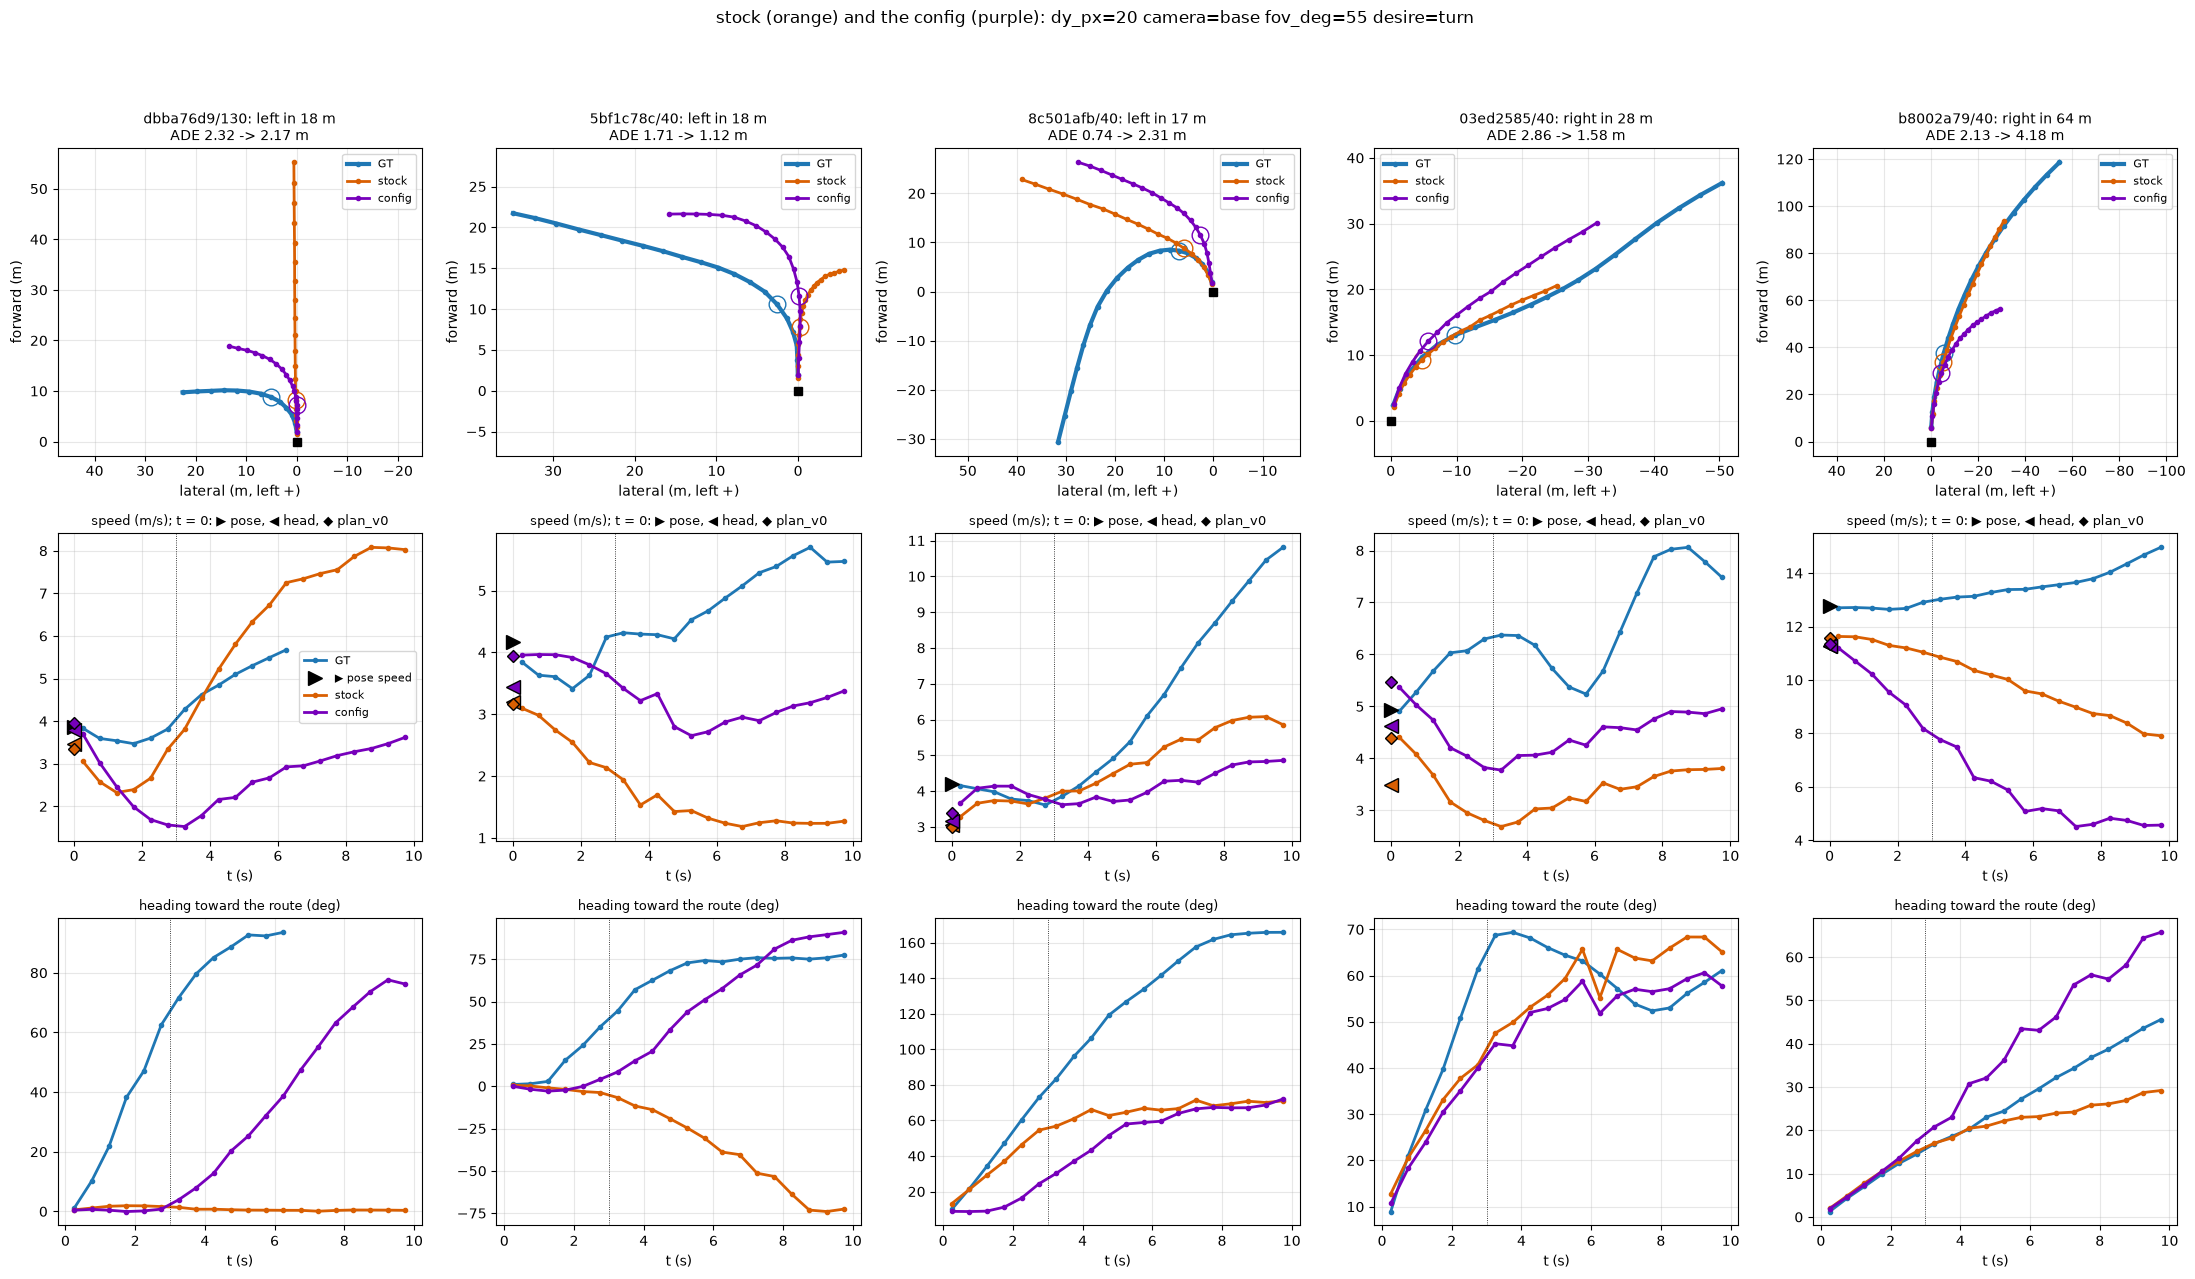

In [12]:
lab.compare(CONFIG, against=AGAINST)

## 5 Several configs side by side

`ARMS` names up to five configs, each written like `CONFIG` (only the knobs it changes). The cell plans all five turns with each, and shows:

1. **The arms**, each with the knobs it changes. In the figures each arm keeps the colour of its place in the list: the first is orange, the second purple, then pink, green and lilac. Adding an arm at the end leaves the others' colours as they were.
2. **Each turn**, every arm's metrics side by side.
3. **The means over the turns.** Each later arm is judged against the first, with part 4's noise floor for the first arm: on each criterion, a verdict and how many turns got better, stayed within the floor, and got worse. Then, without verdicts, the count of plans that turn toward the route and the mean `p_turn`.
4. **Each turn drawn**: the paths, the speeds and the headings, one colour per arm.

**Put the baseline first.** To ask what intent does, compare stock and stock with `desire="turn"`; to ask it on the base camera, compare `camera="base"` with and without it. The commented arms below cover the four combinations of camera and intent, the EON cut, and a lane-change control.

The committed output has only the one arm, stock, so it shows stock's own numbers and no verdicts.

**The arms**

- **stock**: stock

**Each turn** (run here on cpu)

,ade,path_err,dpsi_err,turn_frac,speed_rmse,v0_ratio,head_ratio,p_turn,mode
,stock,stock,stock,stock,stock,stock,stock,stock,stock
dbba76d9/130,2.318,0.850,-60.371,-0.002,0.948,0.798,0.896,0.001,not_planned
5bf1c78c/40,1.710,0.336,-38.391,-0.957,1.221,0.805,0.766,0.136,wrong_way
8c501afb/40,0.744,0.250,-21.619,0.371,0.413,0.792,0.725,0.478,understeer
03ed2585/40,2.864,0.200,-24.608,1.004,2.443,0.898,0.710,0.321,understeer
b8002a79/40,2.132,0.383,-0.113,0.614,1.368,0.916,0.883,0.000,matched


**Means over the 5 turns.** Each verdict is that arm against **stock**, beyond what eight half-pixel shifts of it do; in brackets, the turns better / the same / worse.

,judges,stock,"noise, mean"
criterion,,,
ADE over 3 s (m),ADE,1.953,0.026
ADE over the GT's length (m),ADE,13.462,0.377
lateral error over 3 s (m),alignment,1.037,0.073
distance from the GT's path over 3 s (m),alignment,0.404,0.123
|heading error| over 3 s (deg),alignment,29.020,1.104
speed RMSE over 3 s (m/s),speed profile,1.279,0.028
|1 - start speed / the GT's|,speed profile,0.158,0.004
|1 - pose head / pose speed|,speed profile,0.204,0.012
"turns planned toward the route (count, higher is better)",alignment,3.000,NaN


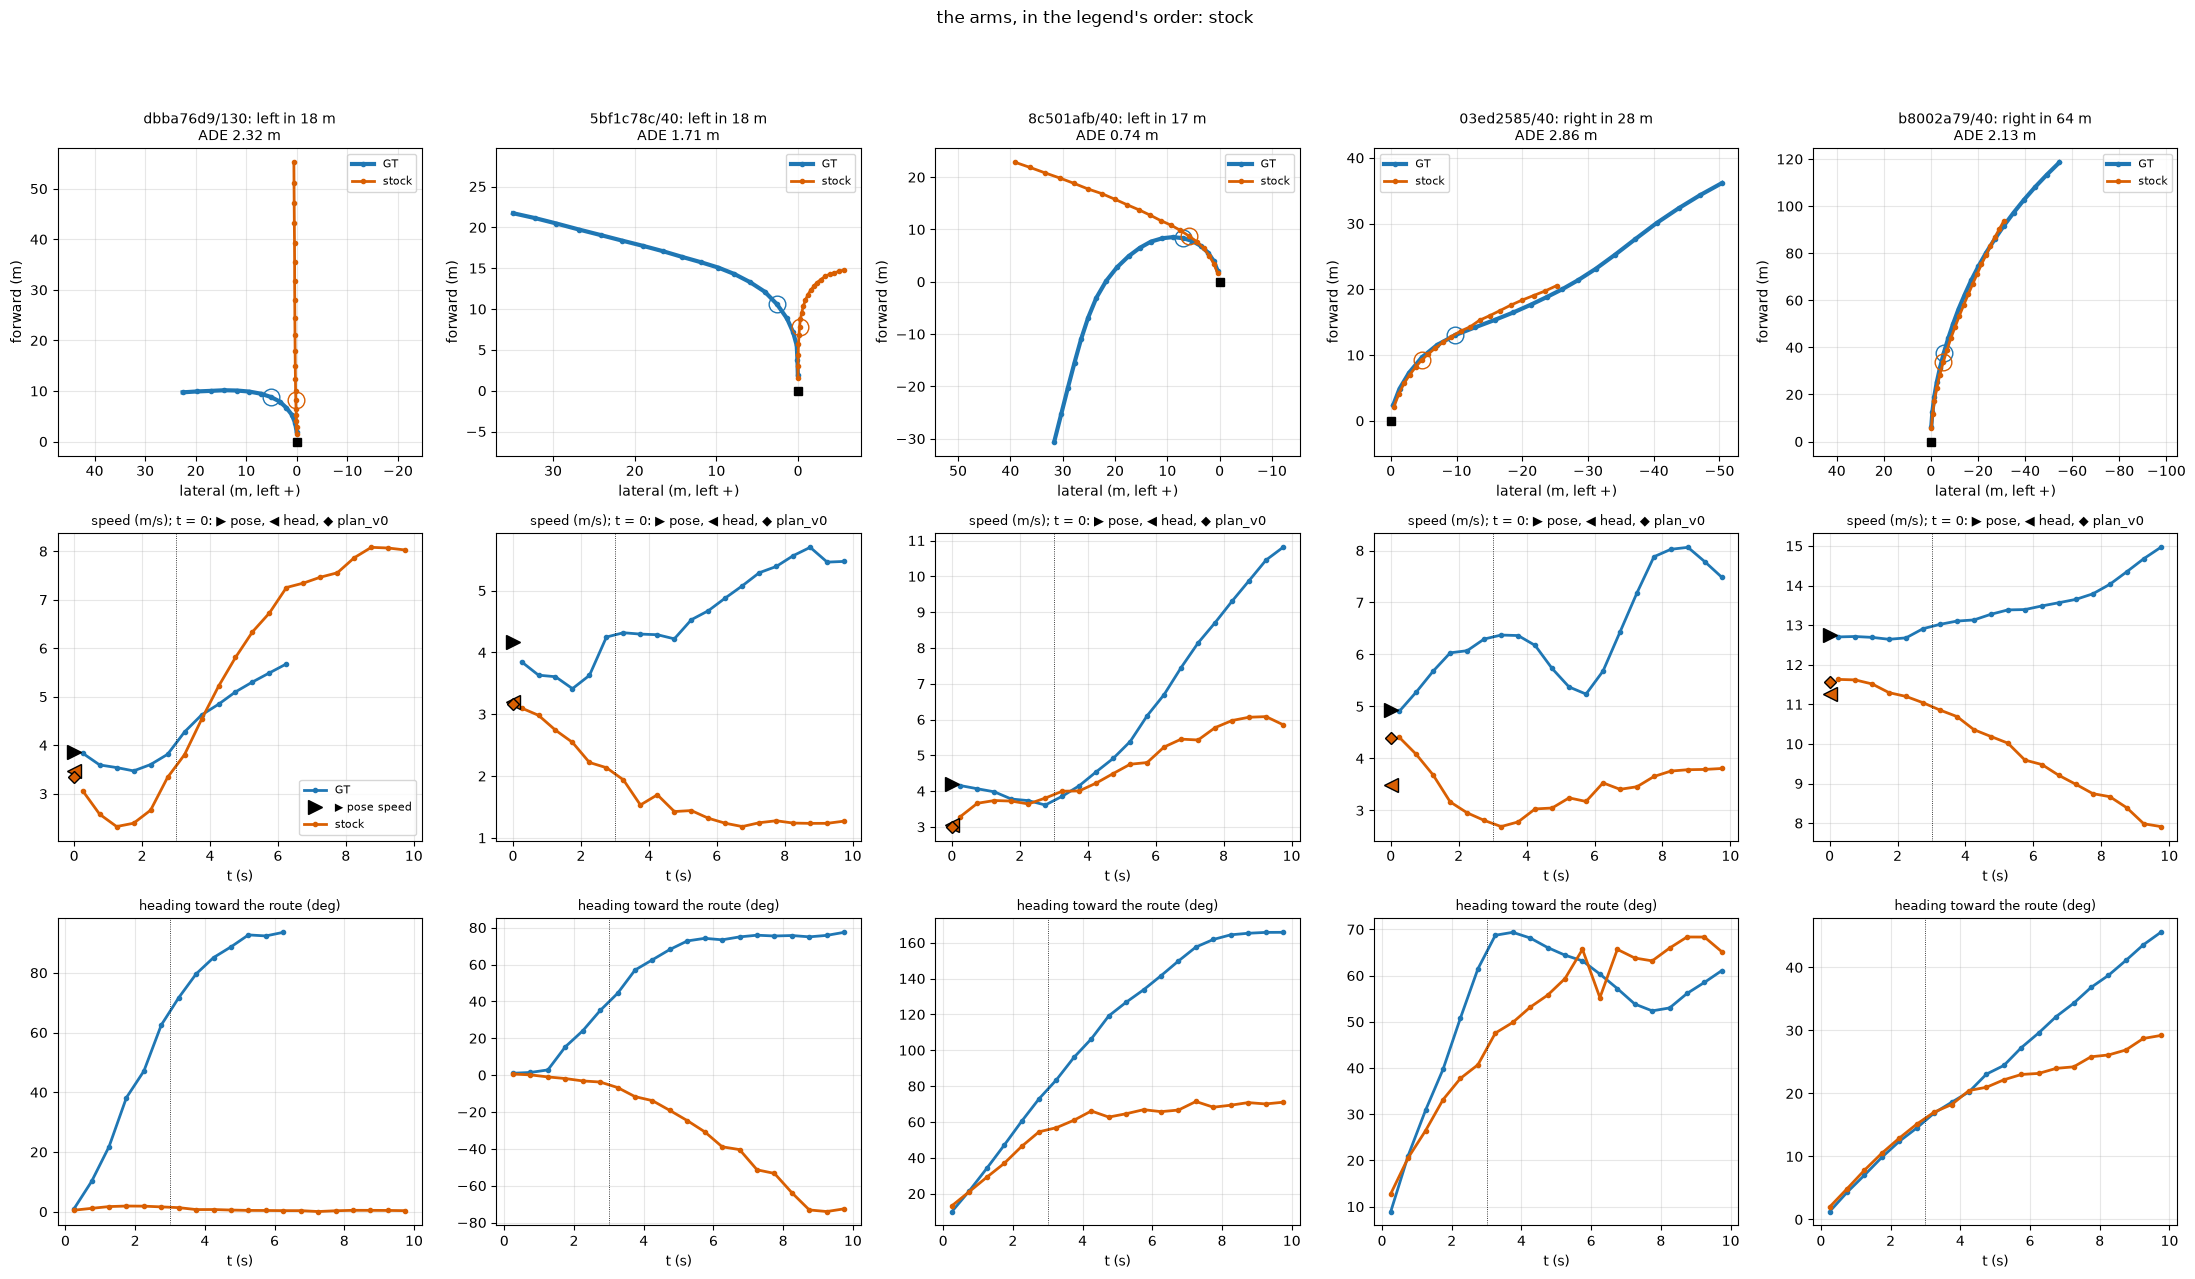

In [13]:
ARMS = {
    "stock": {},
    # "intent": dict(desire="turn"),
    # "lane-change desire": dict(desire="lane_change"),  # the control for "intent"
    # "base camera": dict(camera="base"),
    # "base + intent": dict(camera="base", desire="turn"),
    # "EON cut": dict(fov_deg=T.EON_FOV),
    # "config": CONFIG,
    # "config + base + intent": CONFIG | dict(camera="base", desire="turn"),
}

lab.arms(ARMS)

## Stopping the nodes

The nodes also stop when the kernel stops, and start again on the next call that needs one.

In [14]:
lab.close()